<a href="https://colab.research.google.com/github/MarcinPlodzien/deep-learning-for-classical-and-quantum-physics/blob/main/notebooks/lecture-09/lab-046-echo-state-networks.ipynb"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open in Colab"></a>

<hr/>
# Deep Learning in Classical and Quantum Physics
2026/2027 <br>
**Author:** Marcin Płodzień <br>
**Lab:** 046 <br>
<hr/>

# Lab 046 — Echo state networks

A recurrent neural network keeps a state $\mathbf h_k$ that is updated by every new input value and learns all of its weights by gradient descent through time. Reservoir computing keeps the driven dynamical system and drops the training of its couplings. The state $\mathbf r_k$ of a fixed, randomly coupled nonlinear system is driven by the measured signal, and only a linear readout of this state is fitted, by one ridge regression [H. Jaeger, GMD Report 148 (2001), [pdf](https://www.ai.rug.nl/minds/uploads/EchoStatesTechRep.pdf); W. Maass, T. Natschläger, H. Markram, Neural Comput. **14**, 2531 (2002), [doi:10.1162/089976602760407955](https://doi.org/10.1162/089976602760407955); M. Lukoševičius, H. Jaeger, Comput. Sci. Rev. **3**, 127 (2009), [doi:10.1016/j.cosrev.2009.03.005](https://doi.org/10.1016/j.cosrev.2009.03.005)]. The echo state network (ESN) is the version of this idea with tanh units.

We first define the leaky ESN, its spectral radius, leak rate and input scaling, and the ridge readout, and we check our ESN implementation in JAX against the ReservoirPy library. We then test the three properties a reservoir needs. The echo state property says that the state forgets its initial condition, the memory capacity measures how much of the input history a linear readout can recover, and the nonlinear autoregressive moving-average task (NARMA) asks for memory and products of past inputs at once. With these tools we forecast five benchmark signals, the Lorenz-63 flow, the Mackey–Glass delay equation at three delays and the measured Santa Fe laser intensity, with the same protocol and scores as the autoregressive (AR) and nonlinear vector autoregressive (NVAR) baselines. The notebook ends with the variation between random reservoirs, the dependence on the reservoir size, a short guide to the choice of the reservoir parameters and the cost of the fit.

The implementation uses JAX in double precision. Every reservoir runs as one `jax.lax.scan` over time, and the ridge regressions are checked against scikit-learn.

> **Running this notebook in Google Colab**
> 1. Go to <https://colab.research.google.com> and choose *File, Upload notebook*. The first code cell sets `JAX_PLATFORMS=cpu`. The recorded run of the whole notebook took 4 minutes on a multi-core CPU that was shared with other jobs.
> 2. `jax`, `scikit-learn` and `matplotlib` are pre-installed in Colab. ReservoirPy is installed with `pip install reservoirpy`.
> 3. The first code cell downloads the data file into a folder `data` next to the notebook. It is the data set A of the Santa Fe time-series competition, distributed with the notebooks on recurrent networks.
> 4. The cost section compares the reservoir with trained networks. Their scores, fit times and parameter counts are read from the file `numbers_lab036.json`, written by the notebook on trained recurrent networks. Upload it next to the notebook as well. Without it the cost section shows the models of this notebook only.
> 5. Run the cells in order. Later cells use variables defined earlier.

In [ ]:
# data files of this notebook, downloaded from the course repository if they are not in ./data
import os, urllib.request
os.makedirs("data", exist_ok=True)
for name in ['santafe_laser.txt']:
    if not os.path.exists(f"data/{name}"):
        urllib.request.urlretrieve(f"https://raw.githubusercontent.com/MarcinPlodzien/deep-learning-for-classical-and-quantum-physics/main/notebooks/lecture-09/data/{name}", f"data/{name}")

In [1]:
import os
os.environ["JAX_PLATFORMS"] = "cpu"     # run JAX on the CPU (set before importing jax)

import json, time
from functools import partial
import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.patches import Circle, Ellipse
from matplotlib.lines import Line2D

import jax, jax.numpy as jnp
jax.config.update("jax_enable_x64", True)   # all computations of this notebook in float64
import sklearn
from sklearn.linear_model import Ridge as SkRidge
import reservoirpy
from reservoirpy.nodes import Reservoir, Ridge as RpyRidge
from reservoirpy.datasets import narma as rpy_narma

# common style of the notebook figures
mpl.rcParams.update({"font.size": 14, "axes.labelsize": 15, "axes.titlesize": 15,
                     "xtick.labelsize": 13, "ytick.labelsize": 13, "legend.fontsize": 12,
                     "figure.titlesize": 16, "lines.linewidth": 2.0,
                     "axes.spines.top": False, "axes.spines.right": False, "legend.frameon": False})
# slide figures are drawn at their printed size (5.5 in = full width of a slide), so these are true font sizes
SLIDE_RC = {"font.size": 11, "axes.labelsize": 11, "axes.titlesize": 11, "xtick.labelsize": 11,
            "ytick.labelsize": 11, "legend.fontsize": 11, "lines.linewidth": 1.4, "figure.dpi": 150}

UJBlue, UJNavy, DSOrange, UJGray = "#005CA7", "#002B5C", "#D35A05", "#5A6270"
# one colour and line style per model, used in every figure
STYLE = {"persistence": dict(color="0.55", ls=":"), "AR": dict(color="0.35", ls="--"),
         "NVAR": dict(color=DSOrange, ls="--"), "ESN": dict(color=UJBlue, ls="-"),
         "MLP": dict(color="#7B4FA0", ls="-"), "RNN": dict(color="#2A9D8F", ls="-"),
         "GRU": dict(color="#8C564B", ls="-"), "LSTM": dict(color="#C44E52", ls="-")}
def model_legend(ax, models, **kw):
    # legend built from the line styles of STYLE, so that every swatch has the colour of its curve
    ax.legend([Line2D([], [], lw=1.6, **STYLE[m]) for m in models], models, **kw)

OUT = "figures"
os.makedirs(OUT, exist_ok=True)
def save(fig, name):
    # slide figures are created at their printed size and saved as PDF (slides) and PNG
    for ext in ("pdf", "png"):
        fig.savefig(f"{OUT}/{name}.{ext}", dpi=300, bbox_inches="tight", pad_inches=0.02)

def find_file(name, *extra):
    # look next to the notebook first, then in the usual subfolders and in the given folders
    for d in ("", "data", "figures") + extra:
        p = os.path.join(d, name)
        if os.path.exists(p):
            return p
    return None

nums = {}                 # every number a slide may need, written to the numbers file at the end
t_start = time.time()
print("jax", jax.__version__, "| reservoirpy", reservoirpy.__version__, "| scikit-learn", sklearn.__version__)

jax 0.11.0 | reservoirpy 0.4.1 | scikit-learn 1.6.1


<hr/>
## 1. Signals and forecasting protocol

We use five signals. The first coordinate $x$ of the Lorenz-63 system
$$\dot x=10\,(y-x),\qquad \dot y=x\,(28-z)-y,\qquad \dot z=xy-\tfrac83\,z$$
is integrated by the fourth-order Runge–Kutta method (RK4) and sampled every $\Delta t=0.02$. The Mackey–Glass delay equation
$$\dot s(t)=\frac{0.2\, s(t-\tau_{\rm MG})}{1+s(t-\tau_{\rm MG})^{10}}-0.1\, s(t)$$
is sampled once per time unit for the delays $\tau_{\rm MG}=15$, $25$ and $35$. At $\tau_{\rm MG}=15$ the signal repeats itself after one period, and the AR baseline below forecasts it almost perfectly over 50 steps. At 25 and 35 it is irregular and harder for a linear forecast. The total capacity of the AR baseline, defined below with the maximum 50, drops from 49.8 at $\tau_{\rm MG}=15$ to 33.1 at 25 and 38.0 at 35, while NVAR and the reservoir reach between 45.5 and 49.8 at these two delays. The Santa Fe laser series (data set A) is the measured intensity of a far-infrared NH$_3$ laser, regular pulsations whose amplitude grows until it collapses at irregular times.

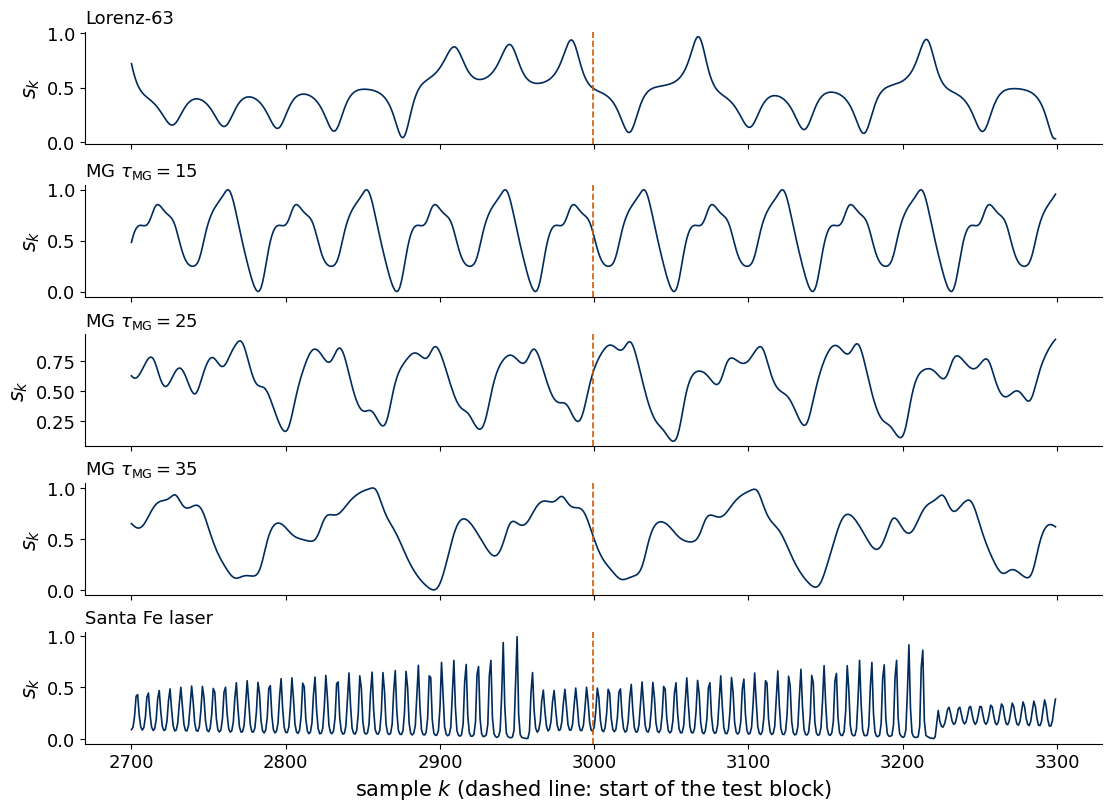

In [2]:
# Lorenz-63: x' = 10 (y - x), y' = x (28 - z) - y, z' = x y - 8/3 z; RK4 with h=0.01, sampled every 2 steps (dt=0.02);
# initial state (1,1,1), first 50 time units discarded; we keep the x component.
def lorenz_rhs(u):
    x, y, z = u
    return jnp.array([10.0 * (y - x), x * (28.0 - z) - y, x * y - 8.0 / 3.0 * z])

def rk4_step(f, u, h):
    k1 = f(u); k2 = f(u + 0.5*h*k1); k3 = f(u + 0.5*h*k2); k4 = f(u + h*k3)
    return u + h/6.0*(k1 + 2*k2 + 2*k3 + k4)

@partial(jax.jit, static_argnums=(0, 1, 2))
def lorenz_trajectory(n_samples, sub=2, n_discard=2500, h=0.01):
    """Returns array (n_samples, 3) sampled every `sub` RK4 steps (dt = sub*h)."""
    def one_sample(u, _):
        u = jax.lax.fori_loop(0, sub, lambda i, v: rk4_step(lorenz_rhs, v, h), u)
        return u, u
    u0 = jnp.array([1.0, 1.0, 1.0])
    u, _ = jax.lax.scan(one_sample, u0, None, length=n_discard)
    _, traj = jax.lax.scan(one_sample, u, None, length=n_samples)
    return traj

# Mackey-Glass: ds/dt = 0.2 s(t-tau)/(1+s(t-tau)^10) - 0.1 s(t);
# RK4 with h=0.1, the delayed value at half steps by linear interpolation, constant history
# s=1.2 on [-tau, 0], first 3000 fine steps discarded, every 10th point kept (unit sampling).
def mackey_glass(tau, n_samples, h=0.1, x0=1.2, transient=3000, every=10):
    lag = int(round(tau / h))
    f = lambda x, xd: 0.2 * xd / (1.0 + xd**10) - 0.1 * x
    def step(buf, _):
        # buf = (x[i-lag], ..., x[i]) : the delay window, length lag+1
        x, xd0, xd1 = buf[-1], buf[0], buf[1]
        xdh = 0.5 * (xd0 + xd1)
        k1 = f(x, xd0); k2 = f(x + 0.5*h*k1, xdh); k3 = f(x + 0.5*h*k2, xdh); k4 = f(x + h*k3, xd1)
        xn = x + h/6.0*(k1 + 2*k2 + 2*k3 + k4)
        return jnp.concatenate([buf[1:], xn[None]]), xn
    n_steps = transient + n_samples * every
    _, xs = jax.lax.scan(step, jnp.full(lag + 1, x0), None, length=n_steps)
    x = np.concatenate([np.full(lag + 1, x0), np.asarray(xs)])
    return x[transient::every][:n_samples]

def santafe():
    # Santa Fe laser data, set A: measured intensity of a far-infrared NH3 laser (next to the notebook first)
    path = find_file("santafe_laser.txt", "../../Lecture_8/Notebooks/data", "../../Lecture_7/Notebooks/data")
    if path is None:
        raise FileNotFoundError("santafe_laser.txt: upload the data file next to the notebook")
    return np.loadtxt(path).astype(float)

# Common protocol: N = 4000 samples per signal; train = first 3000 (last 500 of them = validation),
# test = last 1000; rescale to [0,1] with min/max of the training block; horizons tau = 1..50.
N_SAMPLES, N_TRAIN, N_VAL, TAU_MAX = 4000, 3000, 500, 50
def rescale01(s, n_train=N_TRAIN):
    lo, hi = s[:n_train].min(), s[:n_train].max()
    return (s - lo) / (hi - lo)

raw = {"Lorenz": np.asarray(lorenz_trajectory(N_SAMPLES)[:, 0]),
       "MG15": mackey_glass(15, N_SAMPLES), "MG25": mackey_glass(25, N_SAMPLES),
       "MG35": mackey_glass(35, N_SAMPLES), "SantaFe": santafe()[:N_SAMPLES]}
SIGNALS = list(raw)
LABEL = {"Lorenz": "Lorenz-63", "MG15": r"MG $\tau_{\rm MG}=15$", "MG25": r"MG $\tau_{\rm MG}=25$",
         "MG35": r"MG $\tau_{\rm MG}=35$", "SantaFe": "Santa Fe laser"}
sig = {name: rescale01(x) for name, x in raw.items()}     # [0, 1] on the training block (first 3000 samples)

fig, axs = plt.subplots(5, 1, figsize=(11, 8), sharex=True, layout="constrained")
for ax, name in zip(axs, SIGNALS):
    ax.plot(np.arange(2700, 3300), sig[name][2700:3300], color=UJNavy, lw=1.2)
    ax.axvline(N_TRAIN - 0.5, color=DSOrange, ls="--", lw=1.2)
    ax.set_ylabel(r"$s_k$"); ax.set_title(LABEL[name], loc="left", fontsize=13)
axs[-1].set_xlabel("sample $k$ (dashed line: start of the test block)")
plt.show()

Every signal has 4000 samples, split in time order. The first 3000 form the training block, and its last 500 samples serve as validation. The final 1000 samples are the test block. Each signal is rescaled to $[0,1]$ with the minimum and maximum of the training block only, so the test block may slightly exceed this interval.

A forecast is made at an origin $k$ from the past $s_k,s_{k-1},\dots$ and returns all horizons $\tau=1,\dots,50$ at once, one output per horizon, with the target vector
$$\mathbf y_k=(s_{k+1},\dots,s_{k+50})\in\mathbb R^{50}.$$
The origins are chosen so that no target crosses a block boundary. Fitting uses the origins $k=63,\dots,2449$, validation the origins $k=2499,\dots,2949$ and testing the origins $k=2999,\dots,3949$. The first fitting origin is fixed by the longest delay window of the AR baseline below, 64 values $s_k,\dots,s_{k-63}$, and all models use the same origins, so that their scores are computed on identical targets. Every choice of a setting, for every model, is made on the validation origins, and the test block is used only for the final scores.

In [3]:
L_WIN = 64                                                        # longest delay window of the AR and NVAR baselines
K_FIT = np.arange(L_WIN - 1, N_TRAIN - N_VAL - TAU_MAX)           # origins 63..2449
K_VAL = np.arange(N_TRAIN - N_VAL - 1, N_TRAIN - TAU_MAX)         # origins 2499..2949
K_TEST = np.arange(N_TRAIN - 1, N_SAMPLES - TAU_MAX)              # origins 2999..3949
TAUS = np.arange(1, TAU_MAX + 1)

def targets(s, ks):
    # rows Y[i] = (s_{k+1}, ..., s_{k+50}) for k = ks[i]
    return s[ks[:, None] + TAUS[None, :]]

assert (K_FIT + TAU_MAX).max() < N_TRAIN - N_VAL and (K_VAL + TAU_MAX).max() < N_TRAIN
assert K_TEST[0] + 1 == N_TRAIN and (K_TEST + TAU_MAX).max() == N_SAMPLES - 1
print(f"origins: fit {len(K_FIT)} ({K_FIT[0]}..{K_FIT[-1]}), validation {len(K_VAL)} ({K_VAL[0]}..{K_VAL[-1]}),"
      f" test {len(K_TEST)} ({K_TEST[0]}..{K_TEST[-1]})")
nums["protocol"] = dict(L=L_WIN, n_fit=len(K_FIT), n_val=len(K_VAL), n_test=len(K_TEST), tau_max=TAU_MAX)

origins: fit 2387 (63..2449), validation 451 (2499..2949), test 951 (2999..3949)


### Scores

For each horizon $\tau$ we compare the predictions $\hat s_{k+\tau}$ with the true values $s_{k+\tau}$ over the test origins. The Pearson coefficient $r(\tau)$ measures how well the prediction follows the truth, and the forecast capacity
$$C(\tau)=r(\tau)^2\in[0,1]$$
is its square. The total capacity $C_{\rm tot}=\sum_{\tau=1}^{50}C(\tau)\le 50$ summarises a whole curve, and the skill horizon $\tau_{1/2}$ is the first horizon with $C(\tau)<0.5$. The normalised mean-square error $\mathrm{NMSE}=\langle(\hat s-s)^2\rangle/\mathrm{Var}(s)$ is used for the NARMA task and for one-step forecasts.

In [4]:
@jax.jit
def nmse_and_r(pred, true):
    # pred, true: (n, m); averages over the n rows, one value per column
    err = jnp.mean((pred - true) ** 2, axis=0) / jnp.var(true, axis=0)
    pc, tc = pred - pred.mean(0), true - true.mean(0)
    r = jnp.sum(pc * tc, 0) / jnp.sqrt(jnp.sum(pc ** 2, 0) * jnp.sum(tc ** 2, 0))
    return err, r

def score(pred, true):
    # dictionary with NMSE(tau), r(tau), C(tau) = r^2, C_tot and the skill horizon tau_1/2
    e, r = (np.asarray(a) for a in nmse_and_r(jnp.asarray(pred, jnp.float64), jnp.asarray(true, jnp.float64)))
    C = r ** 2
    below = np.nonzero(C < 0.5)[0]
    return dict(nmse=e, r=r, C=C, Ctot=float(C.sum()), tau_half=int(below[0] + 1) if len(below) else None)

# check the JAX scores against numpy on random data
rng = np.random.default_rng(0)
a, b = rng.normal(size=(500, TAU_MAX)), rng.normal(size=(500, TAU_MAX))
sc = score(a + 0.5 * b, b)
r_np = np.array([np.corrcoef(a[:, j] + 0.5 * b[:, j], b[:, j])[0, 1] for j in range(TAU_MAX)])
print("max |r_JAX - r_numpy| =", np.abs(sc["r"] - r_np).max())

max |r_JAX - r_numpy| = 6.106226635438361e-16


<hr/>
## 2. Reservoir computing

The recurrent neural network (RNN) cell
$$\mathbf h_k=\tanh\big(W_h\mathbf h_{k-1}+W_x s_k+\mathbf b_h\big)$$
is a driven nonlinear dynamical system. Training adjusts $W_h$, $W_x$ and $\mathbf b_h$ by backpropagation through time, whose gradients pass through a product of Jacobians over all time steps and tend to vanish or explode. A reservoir keeps the same kind of driven system and draws its couplings at random once. Its state $\mathbf r_k\in\mathbb R^N$ is a fixed nonlinear function of the input history, and the forecast is a linear readout
$$\hat{\mathbf y}_k=W_{\rm out}^\top\mathbf r_k+\mathbf b .$$
Only $W_{\rm out}$ and the offset $\mathbf b$ are fitted, and this is a linear least-squares problem.

The Koopman picture explains why a linear readout can forecast a nonlinear system [B. O. Koopman, PNAS **17**, 315 (1931), [doi:10.1073/pnas.17.5.315](https://doi.org/10.1073/pnas.17.5.315)]. The flow $\mathbf x_k\mapsto\mathbf x_{k+1}$ of the underlying system is nonlinear, but it acts linearly on functions of the state, the observables. A small example shows the mechanism. The map $x_{k+1}=a\,x_k$, $y_{k+1}=b\,y_k+x_k^2$ is nonlinear in $(x,y)$, and the three observables $(x,\,y,\,x^2)$ evolve by a matrix,
$$\begin{pmatrix}x\\ y\\ x^2\end{pmatrix}_{k+1}=\begin{pmatrix}a&0&0\\0&b&1\\0&0&a^2\end{pmatrix}\begin{pmatrix}x\\ y\\ x^2\end{pmatrix}_{k},$$
so every future value of $y$ is a linear function of these three numbers. For a chaotic system a finite set of observables that closes in this way is in general not available, and a finite set on which the dynamics acts approximately linearly turns forecasting into an approximate linear regression. AR uses the delay window $(s_k,\dots,s_{k-p+1})$ as such a set, and NVAR adds all pairwise products, a few features chosen in advance. A reservoir driven by the measured signal $s_k$ generates $N$ nonlinear features of the record, a random nonlinear lifting of the history, and the readout selects a linear combination of them [E. Bollt, Chaos **31**, 013108 (2021), [doi:10.1063/5.0024890](https://doi.org/10.1063/5.0024890)]. The drawing shows the architecture. The input weights $\mathbf w_{\rm in}$ (dashed blue) and the sparse recurrent couplings $W$ (grey arrows) are random and fixed, and only the readout $W_{\rm out}$ (orange) is trained.

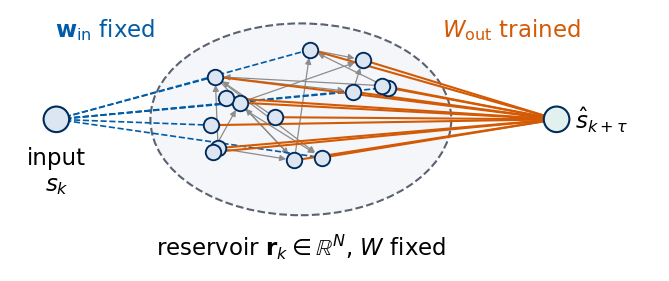

In [5]:
with mpl.rc_context(SLIDE_RC):
    fig, ax = plt.subplots(figsize=(5.5, 2.4))
    rng = np.random.default_rng(3)
    n_res = 14                                           # nodes drawn (the reservoir has N of them)
    ang = rng.uniform(0, 2 * np.pi, n_res); rad = np.sqrt(rng.uniform(0.05, 1, n_res))
    P = np.c_[3.6 + 1.55 * rad * np.cos(ang), 1.2 + 0.95 * rad * np.sin(ang)]
    ax.add_patch(Ellipse((3.6, 1.2), 4.0, 2.55, fc="#F4F6F9", ec=UJGray, ls="--", lw=1.0, zorder=0))
    for i in range(n_res):                               # fixed random recurrent couplings W (sparse)
        for j in range(n_res):
            if i != j and rng.random() < 0.13:
                ax.annotate("", xy=P[j], xytext=P[i], arrowprops=dict(arrowstyle="-|>", color="0.55", lw=0.6,
                            shrinkA=4, shrinkB=4, mutation_scale=6), zorder=1)
    s_xy, y_xy = np.array([0.35, 1.2]), np.array([7.0, 1.2])
    for i in rng.choice(n_res, 7, replace=False):        # fixed input couplings w_in
        ax.plot(*np.c_[s_xy, P[i]], color=UJBlue, lw=0.8, ls="--", zorder=1)
    for i in range(n_res):                               # trained readout W_out
        ax.plot(*np.c_[P[i], y_xy], color=DSOrange, lw=1.0, zorder=1)
    ax.scatter(*P.T, s=55, color="#DCE6F2", edgecolor=UJNavy, lw=0.9, zorder=3)
    ax.add_patch(Circle(s_xy, 0.17, fc="#DCE6F2", ec=UJNavy, zorder=3))
    ax.add_patch(Circle(y_xy, 0.17, fc="#E3F1EE", ec=UJNavy, zorder=3))
    ax.text(s_xy[0], 0.85, "input\n" + r"$s_k$", ha="center", va="top")
    ax.text(y_xy[0] + 0.25, 1.2, r"$\hat s_{k+\tau}$", ha="left", va="center")
    ax.text(1.0, 2.3, r"$\mathbf{w}_{\rm in}$ fixed", color=UJBlue, ha="center")
    ax.text(3.6, -0.3, r"reservoir $\mathbf{r}_k\in\mathbb{R}^N$, $W$ fixed", ha="center", va="top")
    ax.text(6.4, 2.3, r"$W_{\rm out}$ trained", color=DSOrange, ha="center")
    ax.set_xlim(-0.2, 8.3); ax.set_ylim(-0.75, 2.6); ax.set_aspect("equal"); ax.axis("off")
    save(fig, "fig_lab046_esn_diagram"); plt.show()

<hr/>
## 3. Leaky echo state network

The leaky ESN updates its state by
$$\mathbf r_k=(1-\alpha)\,\mathbf r_{k-1}+\alpha\tanh\big(W\mathbf r_{k-1}+\mathbf w_{\rm in}s_k\big),\qquad W=\rho\,\tilde W .$$
The matrix $\tilde W$ is a sparse random $N\times N$ matrix with 10% nonzero Gaussian entries, divided by its spectral radius, the largest modulus of its eigenvalues. We denote the eigenvalues of $\tilde W$ by $\mu_i$, so that $\max_i|\mu_i|=1$, and $W$ has the eigenvalues $\rho\mu_i$ and the spectral radius $\rho$. The input vector $\mathbf w_{\rm in}$ has entries uniform in $[-\sigma_{\rm in},\sigma_{\rm in}]$, and the leak rate $\alpha\in(0,1]$ mixes the old state with the new one. For $\alpha=1$ the update is the RNN cell with random, untrained weights. The input scaling sets how far the units are driven into the nonlinear part of tanh.

The spectral radius and the leak rate together set how slowly the reservoir forgets. Close to $\mathbf r=0$ and for weak input, $\tanh a\approx a$, and the update becomes linear, $\mathbf r_k\approx\big[(1-\alpha)\mathbb 1+\alpha\rho\tilde W\big]\mathbf r_{k-1}$, with the eigenvalues $(1-\alpha)+\alpha\rho\mu_i$. When the eigenvalue of $\tilde W$ of largest modulus is real, $\mu_i=1$, a perturbation along its eigenvector shrinks per step by the factor
$$(1-\alpha)+\alpha\rho ,$$
the effective decay per step. For $\alpha=1$ this is $\rho$, and a perturbation decays as $\rho^k$. For $\alpha<1$ and $\rho<1$ the factor lies between $\rho$ and 1, so a smaller leak rate lengthens the memory. With the formula the memory time $-1/\ln[(1-\alpha)+\alpha\rho]$ is 4.5 steps at $\rho=0.8$ and $\alpha=1$, and 16.2 steps at $\rho=0.8$ and $\alpha=0.3$. When the eigenvalue of largest modulus is complex, the modulus $|(1-\alpha)+\alpha\rho\mu_i|$ of the corresponding eigenvalue of the update is smaller than $(1-\alpha)+\alpha\rho$ for $\alpha<1$, and the formula becomes an upper bound. The printed table compares both for the reservoir with $N=300$.

The figure shows the eigenvalues $\rho\mu_i$ of the reservoir with $N=300$ used for forecasting, for $\rho=0.5$ (grey) and $\rho=0.95$ (blue), with circles of radius $\rho$ and the unit circle (dashed orange). The eigenvalues fill a disc, as expected for a large random matrix. The largest singular value of $\tilde W$ is 1.98, about twice its spectral radius 1, because the matrix is far from symmetric.

N = 300: fraction of nonzero couplings 0.100, spectral radius 1.000, largest singular value 1.98, eigenvalue of largest modulus -0.121+0.993j, largest real part 0.932
alpha = 1.0, rho = 0.5: (1 - alpha) + alpha rho = 0.500, spectral radius of the linearised update = 0.500, memory time -1/ln:   1.4 steps (formula),   1.4 steps (measured)
alpha = 1.0, rho = 0.8: (1 - alpha) + alpha rho = 0.800, spectral radius of the linearised update = 0.800, memory time -1/ln:   4.5 steps (formula),   4.5 steps (measured)
alpha = 1.0, rho = 0.95: (1 - alpha) + alpha rho = 0.950, spectral radius of the linearised update = 0.950, memory time -1/ln:  19.5 steps (formula),  19.5 steps (measured)
alpha = 0.3, rho = 0.5: (1 - alpha) + alpha rho = 0.850, spectral radius of the linearised update = 0.840, memory time -1/ln:   6.2 steps (formula),   5.7 steps (measured)
alpha = 0.3, rho = 0.8: (1 - alpha) + alpha rho = 0.940, spectral radius of the linearised update = 0.924, memory time -1/ln:  16.2 steps (formu

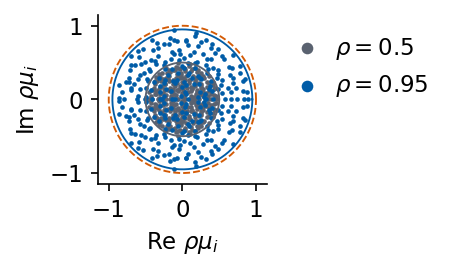

In [6]:
def esn_base(N, seed, density=0.1):
    # random sparse W rescaled to spectral radius 1 and input vector uniform in [-1, 1]; scaled later by rho, sigma_in
    rng = np.random.default_rng(seed)
    W = rng.normal(size=(N, N)) * (rng.random((N, N)) < density)
    W /= np.max(np.abs(np.linalg.eigvals(W)))
    return W, rng.uniform(-1.0, 1.0, size=N)

@jax.jit
def esn_states(W, w_in, u, alpha, x0):
    # r_k = (1 - alpha) r_{k-1} + alpha tanh(W r_{k-1} + w_in u_k), returns all states (T, N)
    def step(x, uk):
        x = (1.0 - alpha) * x + alpha * jnp.tanh(W @ x + w_in * uk)
        return x, x
    _, X = jax.lax.scan(step, x0, u)
    return X

W300, w300 = esn_base(300, seed=0)
mu_eig = np.linalg.eigvals(W300)                     # eigenvalues mu_i of the unit-radius matrix
sv300 = np.linalg.norm(W300, 2)
mu_lead = mu_eig[np.argmax(np.abs(mu_eig))]
nums["W300"] = dict(nonzero_fraction=float((W300 != 0).mean()), sigma_max_rho1=float(sv300),
                    lead_re=float(mu_lead.real), lead_im=float(mu_lead.imag), largest_real=float(mu_eig.real.max()))
print(f"N = 300: fraction of nonzero couplings {(W300 != 0).mean():.3f}, spectral radius {np.abs(mu_eig).max():.3f},"
      f" largest singular value {sv300:.2f}, eigenvalue of largest modulus {mu_eig[np.argmax(np.abs(mu_eig))]:.3f},"
      f" largest real part {mu_eig.real.max():.3f}")

# effective decay per step of the linearised update, (1 - alpha) 1 + alpha W, against the formula (1 - alpha) + alpha rho
nums["decay"] = {}
for a_ in (1.0, 0.3):
    for rho_ in (0.5, 0.8, 0.95):
        lead = np.abs((1 - a_) + a_ * rho_ * mu_eig).max()            # spectral radius of (1 - alpha) 1 + alpha rho W
        decay = (1 - a_) + a_ * rho_
        nums["decay"][f"a{a_}_r{rho_}"] = dict(formula=decay, measured=float(lead), t_mem=float(-1 / np.log(decay)),
                                              t_mem_measured=float(-1 / np.log(lead)))
        print(f"alpha = {a_}, rho = {rho_}: (1 - alpha) + alpha rho = {decay:.3f}, spectral radius of the"
              f" linearised update = {lead:.3f}, memory time -1/ln: {-1 / np.log(decay):5.1f} steps (formula),"
              f" {-1 / np.log(lead):5.1f} steps (measured)")
with mpl.rc_context(SLIDE_RC):
    fig, ax = plt.subplots(figsize=(2.9, 2.6), layout="constrained")
    for rho_, c in ((0.5, UJGray), (0.95, UJBlue)):
        ax.scatter((rho_ * mu_eig).real, (rho_ * mu_eig).imag, s=5, color=c, lw=0, label=rf"$\rho={rho_}$")
        t = np.linspace(0, 2 * np.pi, 200); ax.plot(rho_ * np.cos(t), rho_ * np.sin(t), color=c, lw=0.9)
    t = np.linspace(0, 2 * np.pi, 200); ax.plot(np.cos(t), np.sin(t), color=DSOrange, lw=0.9, ls="--")
    ax.set_aspect("equal"); ax.set_xlim(-1.15, 1.15); ax.set_ylim(-1.15, 1.15)
    ax.set_xlabel(r"Re $\rho\mu_i$"); ax.set_ylabel(r"Im $\rho\mu_i$")
    ax.legend(loc="upper left", bbox_to_anchor=(0.98, 1.0), handletextpad=0.2, markerscale=2.5)
    save(fig, "fig_lab046_spectrum"); plt.show()

For this reservoir the eigenvalue of $\tilde W$ of largest modulus is complex, $\mu_i=-0.121+0.993\,i$, and the largest real part of an eigenvalue is 0.932. For $\alpha=1$ the spectral radius of the linearised update equals $\rho$. For $\alpha=0.3$ it lies slightly below the formula, 0.924 against 0.940 at $\rho=0.8$, which gives a memory time of 12.6 steps, still about 3 times the value at $\alpha=1$. The next figure shows the response of the reservoir ($\rho=0.95$, $\sigma_{\rm in}=0.5$, started from $\mathbf r_0=0$) to the first 300 samples of the rescaled Santa Fe signal $s_k$ (top). The two lower panels plot three components $r_{i,k}$ of the state for $\alpha=1$ and $\alpha=0.3$. Every unit follows the pulsations with its own amplitude, sign and phase, which gives the readout many different nonlinear functions of the record. The smaller leak rate smooths the response and slows it down, and the first tens of steps visibly depend on the start $\mathbf r_0=0$.

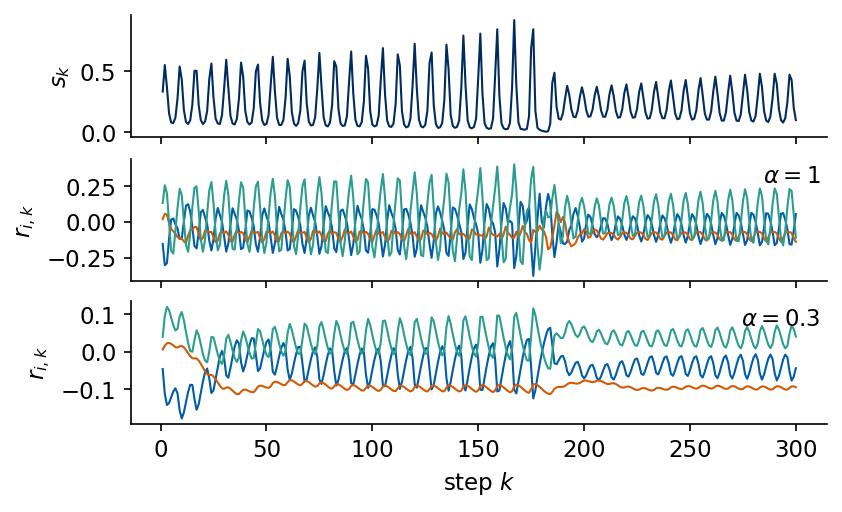

In [7]:
u_sf = sig["SantaFe"]
X_a1 = np.asarray(esn_states(0.95 * W300, 0.5 * w300, u_sf[:300], 1.0, jnp.zeros(300)))
X_a03 = np.asarray(esn_states(0.95 * W300, 0.5 * w300, u_sf[:300], 0.3, jnp.zeros(300)))
units = [0, 1, 2]
with mpl.rc_context(SLIDE_RC):
    fig, axs = plt.subplots(3, 1, figsize=(5.5, 3.3), sharex=True, layout="constrained")
    kk = np.arange(1, 301)
    axs[0].plot(kk, u_sf[:300], color=UJNavy, lw=1.0); axs[0].set_ylabel("$s_k$")
    for ax, X, lab in ((axs[1], X_a1, r"$\alpha=1$"), (axs[2], X_a03, r"$\alpha=0.3$")):
        for i, c in zip(units, (UJBlue, DSOrange, "#2A9D8F")):
            ax.plot(kk, X[:, i], color=c, lw=1.0)
        ax.set_ylabel(r"$r_{i,k}$"); ax.text(0.99, 0.95, lab, transform=ax.transAxes, ha="right", va="top")
    axs[2].set_xlabel("step $k$")
    save(fig, "fig_lab046_states"); plt.show()

### Readout by ridge regression

The rows of the feature matrix $X$ are the states $\mathbf r_k$ at the fitting origins and the rows of $Y$ the targets $\mathbf y_k$. Ridge regression minimises $\sum_k\|\hat{\mathbf y}_k-\mathbf y_k\|^2+\beta\|W_{\rm out}\|^2$ [A. E. Hoerl, R. W. Kennard, Technometrics **12**, 55 (1970), [doi:10.1080/00401706.1970.10488634](https://doi.org/10.1080/00401706.1970.10488634)]. With centred features $X_c$ and centred targets $Y_c$ the solution is one linear solve,
$$W_{\rm out}=\big(X_c^\top X_c+\beta\,\mathbb 1\big)^{-1}X_c^\top Y_c,\qquad \mathbf b=\bar{\mathbf y}-W_{\rm out}^\top\bar{\mathbf r},$$
so the offset is not penalised. The reservoir is driven from the first sample on, starting at $\mathbf r_0=0$, and its first states still remember this arbitrary start. These states form the washout and are left out of the fit. With the common origins of all models the washout is the 63 steps before the first fitting origin, which is long enough when the reservoir forgets its start within 63 steps. How fast it forgets is the subject of the echo state property. The table lists what is trained, what is fixed and what is chosen on validation data.

| role | quantities |
|---|---|
| trained | readout $W_{\rm out}$, $\mathbf b$ |
| fixed, random | couplings $W$, input weights $\mathbf w_{\rm in}$ |
| chosen on validation | $N$, $\rho$, $\sigma_{\rm in}$, $\alpha$, $\beta$ |

The same regression with scikit-learn `Ridge` gives the same predictions up to round-off.

In [8]:
def ridge_fit(F, Y, beta):
    # centred ridge regression, F: (n, d) features, Y: (n, m) targets -> W (d, m), b (m,)
    fm, ym = F.mean(0), Y.mean(0)
    Fc, Yc = F - fm, Y - ym
    W = jnp.linalg.solve(Fc.T @ Fc + beta * jnp.eye(F.shape[1]), Fc.T @ Yc)
    return W, ym - fm @ W

X_chk = np.asarray(esn_states(0.9 * W300, 0.5 * w300, u_sf, 0.3, jnp.zeros(300)))
Wo, bo = ridge_fit(X_chk[K_FIT], targets(u_sf, K_FIT), 1e-4)
sk = SkRidge(alpha=1e-4, fit_intercept=True).fit(X_chk[K_FIT], targets(u_sf, K_FIT))
diff_sk = np.abs(sk.predict(X_chk[K_TEST]) - (X_chk[K_TEST] @ Wo + bo)).max()
print(f"ESN readout, beta = 1e-4: max |prediction JAX - prediction scikit-learn| = {diff_sk:.1e}")
nums["sklearn_diff"] = float(diff_sk)

ESN readout, beta = 1e-4: max |prediction JAX - prediction scikit-learn| = 3.3e-12


<hr/>
## 4. ESN implementation in JAX and in ReservoirPy

ReservoirPy builds the same reservoir as a `Reservoir` node with leak rate `lr` $=\alpha$ and zero bias. We pass our matrices $W$ and $\mathbf w_{\rm in}$ to the library and drive both implementations with the Santa Fe signal.

In [9]:
# the same reservoir in ReservoirPy, with our W and w_in passed in (bias 0, lr = leak rate alpha)
W0, w0 = esn_base(100, seed=0)
rho, sigma_in, alpha = 0.9, 0.5, 0.3
X_jax = np.asarray(esn_states(rho * W0, sigma_in * w0, u_sf, alpha, jnp.zeros(100)))
rpy_res = Reservoir(W=rho * W0, Win=(sigma_in * w0)[:, None], bias=0.0, lr=alpha, input_dim=1)
X_rpy = rpy_res.run(u_sf[:, None])
d_states = np.abs(X_jax - X_rpy).max()
print("states", X_jax.shape, f"| max |r_JAX - r_ReservoirPy| = {d_states:.1e}")
nums["rpy_states_diff"] = float(d_states)

states (4000, 100) | max |r_JAX - r_ReservoirPy| = 3.3e-16


The states agree to $3.3\times10^{-16}$, which is round-off. A complete ReservoirPy model is a reservoir node connected to a ridge node, `Reservoir(...) >> Ridge(ridge=beta)`, fitted with `model.fit(inputs, targets, warmup=63)`, where the first 63 states are discarded. For $N=300$ its readout gives the same test predictions as our ridge solve to $7.0\times10^{-11}$.

In [10]:
# ReservoirPy model = reservoir node >> ridge node, fitted on the origins 63..2449 (warmup = first 63 states)
beta_chk = 1e-4
Y_all = targets(u_sf, np.arange(K_FIT[-1] + 1))                    # targets of the origins 0..2449
model_rpy = Reservoir(W=0.9 * W300, Win=(0.5 * w300)[:, None], bias=0.0, lr=0.3, input_dim=1) >> RpyRidge(ridge=beta_chk)
model_rpy.fit(u_sf[:K_FIT[-1] + 1, None], Y_all, warmup=K_FIT[0])
ridge_node = model_rpy.nodes[-1]
Wo, bo = ridge_fit(X_chk[K_FIT], targets(u_sf, K_FIT), beta_chk)
d_pred = np.abs((X_chk[K_TEST] @ ridge_node.Wout + ridge_node.bias) - (X_chk[K_TEST] @ Wo + bo)).max()
print(f"N = 300, beta = {beta_chk:.0e}: max |prediction JAX - prediction ReservoirPy| = {d_pred:.1e}")
nums["rpy_pred_diff"] = float(d_pred)

N = 300, beta = 1e-04: max |prediction JAX - prediction ReservoirPy| = 7.0e-11


<hr/>
## 5. Echo state property and fading memory

A single linear readout can only work if the state is a function of the input history alone. The echo state property requires that two copies of the reservoir started from different states $\mathbf r_0$ and $\mathbf r_0'$ and driven by the same input approach each other,
$$\|\mathbf r_k-\mathbf r'_k\|\to0\qquad(k\to\infty),$$
for every input sequence with values in a bounded interval, here $[0,1]$. Then $\mathbf r_k$ is an echo of the drive $s_k,s_{k-1},\dots$ [Jaeger, GMD Report 148 (2001)]. Two conditions are known for $\alpha=1$. Since $|\tanh a-\tanh b|\le|a-b|$, the update shrinks distances when the largest singular value of $W$ is below 1, which is sufficient. A spectral radius above 1 makes the zero state unstable for the zero input sequence, $s_k=0$ at every step, so the property fails for this input, and $\rho<1$ is necessary when the zero sequence is among the allowed inputs. No condition is known that is both necessary and sufficient [I. B. Yildiz, H. Jaeger, S. J. Kiebel, Neural Netw. **35**, 1 (2012), [doi:10.1016/j.neunet.2012.07.005](https://doi.org/10.1016/j.neunet.2012.07.005)], so in practice $\rho$ is used as a control parameter and the property is tested directly with the input at hand. For a leaky reservoir, $\alpha<1$, the linearised update multiplies a perturbation along a real leading eigenvector by $(1-\alpha)+\alpha\rho$ per step, which is below 1 for $\rho<1$ and above 1 for $\rho>1$, so the leak rate slows both the contraction and the growth.

We start one reservoir with $N=100$, $\alpha=1$ and $\sigma_{\rm in}=0.5$ from two random states with entries uniform in $[-1,1]$ and drive both copies with the first 500 samples of the rescaled Santa Fe signal. The figure shows the distance $\|\mathbf r_k-\mathbf r'_k\|$ for $\rho=0.8$, $1.0$, $1.2$ and $2.0$, and for $\rho=1.2$ with the input switched off (dashed).

N = 100: largest singular value of W at rho = 1: 2.21, so sigma_max(rho W) < 1 for rho < 0.45


$\rho=0.8$             |r_k - r'_k| at k = 100: 1.04e-10, at k = 500: 3.16e-16, below 1e-14 from k = 138
$\rho=1.0$             |r_k - r'_k| at k = 100: 1.55e-02, at k = 500: 6.80e-12, below 1e-14 from k = None


$\rho=1.2$             |r_k - r'_k| at k = 100: 5.83e+00, at k = 500: 4.71e+00, below 1e-14 from k = None
$\rho=2.0$             |r_k - r'_k| at k = 100: 1.25e+01, at k = 500: 1.02e+01, below 1e-14 from k = None
$\rho=1.2$, no input   |r_k - r'_k| at k = 100: 7.57e+00, at k = 500: 7.36e+00, below 1e-14 from k = None


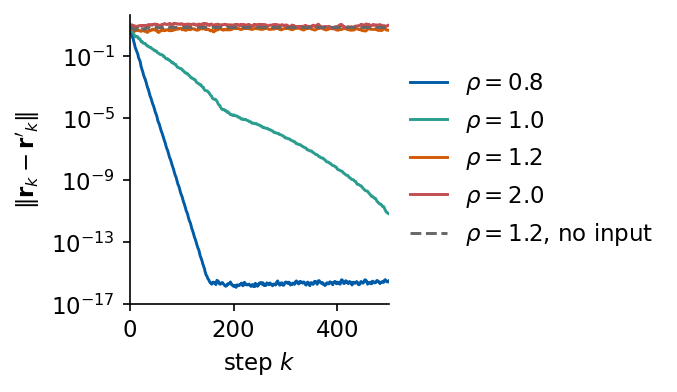

In [11]:
def esp_distance(rho, sigma_in, u, alpha=1.0, seed=1, N=100):
    # distance between two copies of one reservoir started from different random states, same input u
    W, w = esn_base(N, seed=0)
    rng = np.random.default_rng(seed)
    xa, xb = rng.uniform(-1, 1, N), rng.uniform(-1, 1, N)
    Xa = esn_states(rho * W, sigma_in * w, u, alpha, xa)
    Xb = esn_states(rho * W, sigma_in * w, u, alpha, xb)
    return np.linalg.norm(np.asarray(Xa - Xb), axis=1)

T_ESP = 500
u_esp = sig["SantaFe"][:T_ESP]
cases = [(0.8, u_esp, r"$\rho=0.8$", "rho0.8"), (1.0, u_esp, r"$\rho=1.0$", "rho1.0"),
         (1.2, u_esp, r"$\rho=1.2$", "rho1.2"), (2.0, u_esp, r"$\rho=2.0$", "rho2.0"),
         (1.2, 0 * u_esp, r"$\rho=1.2$, no input", "rho1.2_noinput")]
sv100 = np.linalg.norm(esn_base(100, seed=0)[0], 2)
print(f"N = 100: largest singular value of W at rho = 1: {sv100:.2f}, so sigma_max(rho W) < 1 for rho < {1 / sv100:.2f}")
nums["esp"] = dict(sigma_max_rho1=float(sv100), rho_bound=float(1 / sv100))
with mpl.rc_context(SLIDE_RC):
    fig, ax = plt.subplots(figsize=(4.4, 2.5), layout="constrained")
    for (rho_, u, lab, key), c in zip(cases, [UJBlue, "#2A9D8F", DSOrange, "#C44E52", "0.4"]):
        d = esp_distance(rho_, 0.5, u)
        ax.semilogy(np.arange(1, len(d) + 1), np.maximum(d, 1e-17), color=c, ls="--" if "no input" in lab else "-", label=lab)
        k_below = int(np.argmax(d < 1e-14)) + 1 if (d < 1e-14).any() else None
        nums["esp"][key] = dict(d_end=float(d[-1]), d_100=float(d[99]), k_below_1e14=k_below)
        print(f"{lab:22s} |r_k - r'_k| at k = 100: {d[99]:.2e}, at k = {T_ESP}: {d[-1]:.2e}, below 1e-14 from k = {k_below}")
    ax.set_xlabel("step $k$"); ax.set_ylabel(r"$\|\mathbf{r}_k-\mathbf{r}'_k\|$")
    ax.set_ylim(1e-17, 50); ax.set_xlim(0, T_ESP)
    ax.legend(loc="center left", bbox_to_anchor=(1.0, 0.5), handlelength=1.6)
    save(fig, "fig_lab046_esp"); plt.show()

For $\rho=0.8$ the distance decays exponentially and first falls below $10^{-14}$, the round-off level, at step 138. For $\rho=1.0$ the decay is much slower, $1.5\times10^{-2}$ after 100 steps and $6.8\times10^{-12}$ after 500. For $\rho=1.2$ and $2.0$ the distance stays of order one over all 500 steps, and so does the run at $\rho=1.2$ with the input switched off, the only spectral radius run without input. In these cases the state keeps a memory of its start and a readout trained on one run does not transfer to another. The largest singular value of this $W$ at $\rho=1$ is 2.21, so the sufficient condition holds only for $\rho < 0.45$. The convergence at $\rho=0.8$ and $1.0$ is a property of this reservoir and this input that the bound does not guarantee.

The input itself helps the contraction. We repeat the test over a grid of spectral radii for four input scalings, with 1000 input steps and three pairs of starts, and plot the median of the mean distance over the last 100 steps, $\langle\|\mathbf r_k-\mathbf r'_k\|\rangle$. The dotted line marks the sufficient bound $\sigma_{\max}(\rho W)=1$.

sigma_in = 0.1: first rho on the grid with distance > 1e-6 after 1000 steps: 1.0
sigma_in = 0.5: first rho on the grid with distance > 1e-6 after 1000 steps: 1.1
sigma_in = 1.0: first rho on the grid with distance > 1e-6 after 1000 steps: 1.25
sigma_in = 2.0: first rho on the grid with distance > 1e-6 after 1000 steps: 1.45


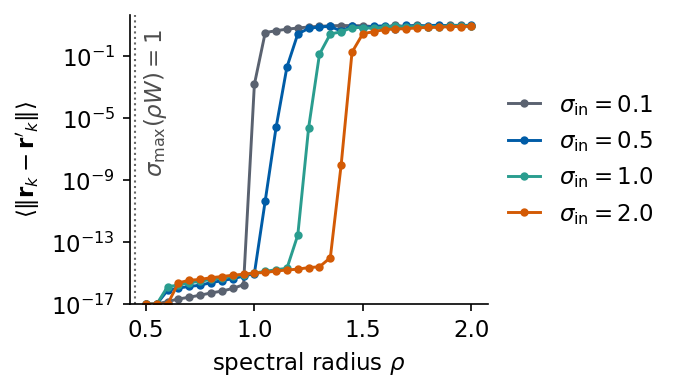

In [12]:
RHO_SCAN = np.round(np.arange(0.5, 2.001, 0.05), 2)
SIG_SCAN = (0.1, 0.5, 1.0, 2.0)
u_scan = sig["SantaFe"][:1000]
esp_map = {}
for si in SIG_SCAN:
    esp_map[si] = np.array([np.median([esp_distance(r_, si, u_scan, seed=sd)[-100:].mean() for sd in (1, 2, 3)])
                            for r_ in RHO_SCAN])
nums["esp_rho_crit"] = {}
for si in SIG_SCAN:
    above = np.nonzero(esp_map[si] > 1e-6)[0]
    rc = float(RHO_SCAN[above[0]]) if len(above) else None
    nums["esp_rho_crit"][str(si)] = rc
    print(f"sigma_in = {si}: first rho on the grid with distance > 1e-6 after 1000 steps: {rc}")
with mpl.rc_context(SLIDE_RC):
    fig, ax = plt.subplots(figsize=(4.4, 2.5), layout="constrained")
    for si, c in zip(SIG_SCAN, (UJGray, UJBlue, "#2A9D8F", DSOrange)):
        ax.semilogy(RHO_SCAN, np.maximum(esp_map[si], 1e-17), "o-", ms=3, color=c, label=rf"$\sigma_{{\rm in}}={si}$")
    ax.axvline(1 / sv100, color="0.4", ls=":", lw=1.0)
    ax.text(1 / sv100 + 0.03, 1e-4, r"$\sigma_{\max}(\rho W)=1$", rotation=90, va="center", ha="left", color="0.3")
    ax.set_xlabel(r"spectral radius $\rho$"); ax.set_ylabel(r"$\langle\|\mathbf{r}_k-\mathbf{r}'_k\|\rangle$")
    ax.set_ylim(1e-17, 50); ax.legend(loc="center left", bbox_to_anchor=(1.0, 0.5), handlelength=1.4)
    save(fig, "fig_lab046_esp_scan"); plt.show()

The distance drops to round-off below a threshold spectral radius and jumps to order one above it. The first grid value of $\rho$ with a distance above $10^{-6}$ is 1.0 for $\sigma_{\rm in}=0.1$, 1.1 for $0.5$, 1.25 for $1.0$ and 1.45 for $2.0$. A strong input drives the units towards saturation, where the derivative $\tanh'$ is small, and this shrinks the effective gain of the recurrence. The usual rule $\rho<1$ is therefore a working rule for weak inputs. For this reservoir and the Santa Fe input at $\sigma_{\rm in}=2$ the two copies converge within 1000 steps up to $\rho=1.4$, the last grid value below the threshold 1.45. The thresholds hold for this one reservoir and input on a grid of step 0.05.

### Fading memory

The echo state property concerns the initial state. Fading memory concerns the inputs. A reservoir has fading memory when two input histories that agree over the recent past and differ only long ago lead to nearly the same present state, with a distance between the two states that goes to zero as the length of the agreement grows. Remote inputs then matter less and less for the present state. Boyd and Chua showed that every time-invariant operator with fading memory can be approximated uniformly by a finite Volterra series, a polynomial of finite degree in past input values [S. Boyd, L. O. Chua, IEEE Trans. Circuits Syst. **32**, 1150 (1985), [doi:10.1109/TCS.1985.1085649](https://doi.org/10.1109/TCS.1985.1085649)]. The two properties differ in what is forgotten, the start of the reservoir for the echo state property and the remote inputs for fading memory. For a reservoir whose update contracts distances both hold together.

We test fading memory with the reservoir of the two-copy test, $N=100$, $\alpha=1$ and $\sigma_{\rm in}=0.5$. Both copies start from $\mathbf r_0=0$. One is driven by the first 500 samples of the rescaled Santa Fe signal, the other by the same samples with the first 50 replaced by random values uniform in $[0,1]$, so the two inputs coincide from step 51 on. The figure shows the distance of the two states for $\rho=0.8$ and $1.2$, with the end of the differing inputs marked by the dotted line.

rho = 0.8: |r_k - r'_k| at k = 50: 1.80e+00, k = 100: 8.32e-06, k = 200: 2.30e-16, k = 500: 3.72e-16
rho = 1.2: |r_k - r'_k| at k = 50: 2.71e+00, k = 100: 1.24e+00, k = 200: 1.21e+00, k = 500: 1.06e+00


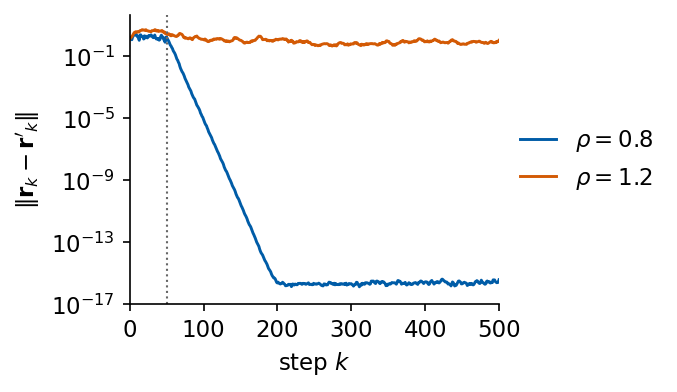

In [13]:
def fading_distance(rho, u_a, u_b, sigma_in=0.5, N=100):
    # two copies of one reservoir started from r_0 = 0 and driven by two different inputs
    W, w = esn_base(N, seed=0)
    Xa = esn_states(rho * W, sigma_in * w, u_a, 1.0, jnp.zeros(N))
    Xb = esn_states(rho * W, sigma_in * w, u_b, 1.0, jnp.zeros(N))
    return np.linalg.norm(np.asarray(Xa - Xb), axis=1)

K_DIFF = 50                                              # the inputs differ during steps 1..50 only
u_fa = sig["SantaFe"][:T_ESP]
u_fb = u_fa.copy(); u_fb[:K_DIFF] = np.random.default_rng(9).uniform(0, 1, K_DIFF)
nums["fading"] = {}
with mpl.rc_context(SLIDE_RC):
    fig, ax = plt.subplots(figsize=(4.4, 2.5), layout="constrained")
    for rho_, c in ((0.8, UJBlue), (1.2, DSOrange)):
        d = fading_distance(rho_, u_fa, u_fb)
        nums["fading"][f"rho{rho_}"] = dict(d_50=float(d[K_DIFF - 1]), d_100=float(d[99]), d_200=float(d[199]), d_end=float(d[-1]))
        ax.semilogy(np.arange(1, len(d) + 1), np.maximum(d, 1e-17), color=c, label=rf"$\rho={rho_}$")
        print(f"rho = {rho_}: |r_k - r'_k| at k = {K_DIFF}: {d[K_DIFF - 1]:.2e}, k = 100: {d[99]:.2e},"
              f" k = 200: {d[199]:.2e}, k = {T_ESP}: {d[-1]:.2e}")
    ax.axvline(K_DIFF, color="0.4", ls=":", lw=1.0)
    ax.set_xlabel("step $k$"); ax.set_ylabel(r"$\|\mathbf{r}_k-\mathbf{r}'_k\|$")
    ax.set_ylim(1e-17, 50); ax.set_xlim(0, T_ESP)
    ax.legend(loc="center left", bbox_to_anchor=(1.0, 0.5), handlelength=1.6)
    save(fig, "fig_lab046_fading"); plt.show()

For $\rho=0.8$ the distance is 1.8 at step 50, falls to $8.3\times10^{-6}$ at step 100 and reaches the round-off level, $2.3\times10^{-16}$, at step 200, so inputs that lie 150 steps or more in the past leave no measurable trace in the state. For $\rho=1.2$ the distance stays of order one, 1.06 at step 500, and the 50 differing inputs are not forgotten within the run. In this test fading memory holds at the spectral radius where the two copies of the echo state test converge and fails where they stay apart.

<hr/>
## 6. Memory capacity

### A linear reservoir of three units

The state of a reservoir stores the past inputs, and a linear reservoir of three units shows how. We feed it an input $u_k$ drawn independently and uniformly from $[-1,1]$ and update $\mathbf r_k=W\mathbf r_{k-1}+\mathbf w_{\rm in}u_k$ without any nonlinearity. For the shift matrix and the input vector
$$W=\begin{pmatrix}0&0&0\\1&0&0\\0&1&0\end{pmatrix},\qquad \mathbf w_{\rm in}=\begin{pmatrix}1\\0\\0\end{pmatrix},$$
the first unit receives the present input and every unit passes its value on to the next one, so the state is the delay line $\mathbf r_k=(u_k,u_{k-1},u_{k-2})$. A linear readout recovers $u_{k-d}$ exactly for the delays $d=0,1,2$ and not at all for $d\ge3$, since $u_{k-3}$ is independent of the three stored numbers. For a random matrix the state is a weighted sum of the whole past,
$$\mathbf r_k=\sum_{m\ge0}W^m\mathbf w_{\rm in}\,u_{k-m},$$
and the three numbers mix all delays, with weights that decay like the powers of $W$. A readout can then recover each delayed input only in part. We fit one least-squares readout per delay on 2000 steps and measure on 1000 further steps the capacity $C(d)=r^2(\hat u_{k-d},u_{k-d})$, for the shift reservoir and for a random $3\times3$ matrix rescaled to $\rho=0.8$.

shift : C(d) for d = 0..12: 1.000, 1.000, 1.000, 0.001, 0.001, 0.002, 0.003, 0.001, 0.000, 0.001, 0.000, 0.000, 0.000 | sum over d >= 0: 3.010, MC (d >= 1): 2.010
random: C(d) for d = 0..12: 0.752, 0.332, 0.332, 0.271, 0.260, 0.252, 0.228, 0.152, 0.042, 0.010, 0.005, 0.005, 0.002 | sum over d >= 0: 2.642, MC (d >= 1): 1.890
shift reservoir: r_k = (u_k, u_{k-1}, u_{k-2}) on all steps k >= 2: True


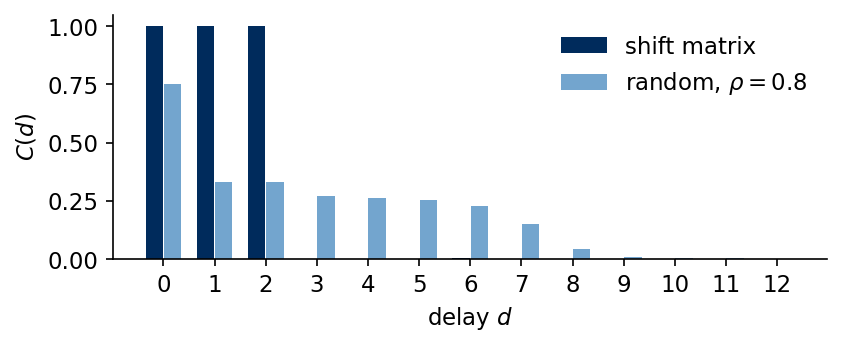

In [14]:
def linear_states(W, w, u):
    # linear reservoir r_k = W r_{k-1} + w u_k, started at r_0 = 0
    r, out = np.zeros(len(w)), []
    for uk in u:
        r = W @ r + w * uk
        out.append(r)
    return np.array(out)

u3 = np.random.default_rng(3).uniform(-1, 1, 3050)
W_shift, w_shift = np.array([[0, 0, 0], [1, 0, 0], [0, 1, 0.0]]), np.array([1.0, 0, 0])
rng3 = np.random.default_rng(4)
W_rand = rng3.normal(size=(3, 3)); W_rand *= 0.8 / np.max(np.abs(np.linalg.eigvals(W_rand))); w_rand = rng3.uniform(-1, 1, 3)
D3 = np.arange(0, 13)
k3_fit, k3_test = np.arange(50, 2050), np.arange(2050, 3050)          # 50 steps of washout
nums["linear3"] = {}
C3 = {}
for name, (W_, w_) in (("shift", (W_shift, w_shift)), ("random", (W_rand, w_rand))):
    R3 = linear_states(W_, w_, u3)
    F_fit, F_test = np.c_[R3[k3_fit], np.ones(len(k3_fit))], np.c_[R3[k3_test], np.ones(len(k3_test))]
    coef = np.linalg.lstsq(F_fit, u3[k3_fit[:, None] - D3[None, :]], rcond=None)[0]   # one column per delay d
    pred, true = F_test @ coef, u3[k3_test[:, None] - D3[None, :]]
    C3[name] = np.array([np.corrcoef(pred[:, j], true[:, j])[0, 1] ** 2 for j in range(len(D3))])
    nums["linear3"][name] = dict(C=C3[name].tolist(), sum_d0=float(C3[name].sum()), MC=float(C3[name][1:].sum()))
    print(f"{name:6s}: C(d) for d = 0..12: " + ", ".join(f"{c:.3f}" for c in C3[name])
          + f" | sum over d >= 0: {C3[name].sum():.3f}, MC (d >= 1): {C3[name][1:].sum():.3f}")
R_shift = linear_states(W_shift, w_shift, u3)
print("shift reservoir: r_k = (u_k, u_{k-1}, u_{k-2}) on all steps k >= 2:",
      np.array_equal(R_shift[2:], np.c_[u3[2:], u3[1:-1], u3[:-2]]))
with mpl.rc_context(SLIDE_RC):
    fig, ax = plt.subplots(figsize=(5.5, 2.2), layout="constrained")
    ax.bar(D3 - 0.18, C3["shift"], 0.34, color=UJNavy, label="shift matrix")
    ax.bar(D3 + 0.18, C3["random"], 0.34, color=UJBlue, alpha=0.55, label=r"random, $\rho=0.8$")
    ax.set_xlabel("delay $d$"); ax.set_ylabel("$C(d)$"); ax.set_ylim(0, 1.05); ax.set_xticks(D3)
    ax.legend(loc="upper right")
    save(fig, "fig_lab046_mc_linear3"); plt.show()

The shift reservoir returns $C(0)=C(1)=C(2)=1$ and at most 0.003 for longer delays, the level that the squared correlation of two independent sequences reaches on 1000 test steps, so its three units hold the last three inputs. The random reservoir spreads its memory over more delays and recovers less in total. Its capacities decrease with the delay, from 0.752 at $d=0$ to 0.271 at $d=3$ and 0.002 at $d=12$, and their sum over the delays 0 to 12 is 2.64, below the 3 of the shift reservoir. Three units cannot store more than three independent numbers, and for an input without correlations this bounds the sum of $C(d)$ over all delays by the number of units [Jaeger, GMD Report 148 (2001)].

### Memory capacity of the ESN

The same measurement applies to the nonlinear ESN. For every delay $d=1,\dots,100$ a separate linear readout of $\mathbf r_k$ is trained to return $u_{k-d}$, and the memory capacity is the sum of its capacities on test data,
$$\mathrm{MC}=\sum_{d=1}^{100}C(d)\le N .$$
For an input without correlations the memory capacity of an ESN is bounded by the number of units [Jaeger, GMD Report 148 (2001); J. Dambre, D. Verstraeten, B. Schrauwen, S. Massar, Sci. Rep. **2**, 514 (2012), [doi:10.1038/srep00514](https://doi.org/10.1038/srep00514)]. We use $N=50$, $\alpha=1$ and a small input scaling $\sigma_{\rm in}=0.1$, so that the units work close to their linear range. After 200 discarded steps we fit the readouts on 4000 steps, choose one ridge strength for all delays by the largest sum of $C(d)$ on the next 1000 steps and measure $C(d)$ on the last 2000 steps. The figure shows $C(d)$ for four spectral radii.

rho = 0.50: MC =  12.3 (bound N = 50), C(d) > 0.5 up to d = 12
rho = 0.80: MC =  17.7 (bound N = 50), C(d) > 0.5 up to d = 18
rho = 0.95: MC =  19.9 (bound N = 50), C(d) > 0.5 up to d = 19
rho = 1.10: MC =  16.8 (bound N = 50), C(d) > 0.5 up to d = 15


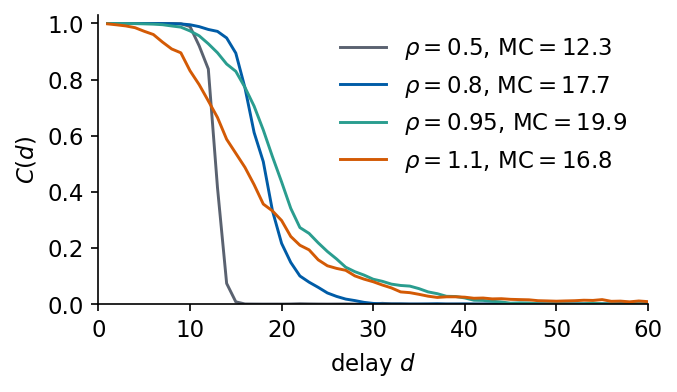

In [15]:
MC_BETAS = (1e-8, 1e-6, 1e-4, 1e-2, 1.0, 1e2)
MC_WASH, MC_FIT, MC_VAL, MC_TEST, D_MAX = 200, 4000, 1000, 2000, 100
k_f = np.arange(MC_WASH, MC_WASH + MC_FIT); k_v = k_f[-1] + 1 + np.arange(MC_VAL); k_t = k_v[-1] + 1 + np.arange(MC_TEST)
Dl = np.arange(1, D_MAX + 1)

def ridge_path(F_fit, Y_fit, betas):
    # centred ridge regressions for several ridge strengths from one eigendecomposition; yields (beta, W, b)
    fm, ym = F_fit.mean(0), Y_fit.mean(0)
    Fc = F_fit - fm
    ev, V = np.linalg.eigh(Fc.T @ Fc)
    P = V.T @ (Fc.T @ (Y_fit - ym))
    for beta in betas:
        W = V @ (P / (ev + beta)[:, None])
        yield beta, W, ym - fm @ W

def r2_columns(pred, true):
    pc, tc = pred - pred.mean(0), true - true.mean(0)
    return (pc * tc).sum(0) ** 2 / ((pc ** 2).sum(0) * (tc ** 2).sum(0))

def memory_curve(X, u):
    # C(d), d = 1..100, on the test steps with the ridge strength chosen by the validation sum of C(d)
    Y = lambda ks: u[ks[:, None] - Dl[None, :]]
    best = (-1, None)
    for beta, W, b in ridge_path(X[k_f], Y(k_f), MC_BETAS):
        v = r2_columns(X[k_v] @ W + b, Y(k_v)).sum()
        if v > best[0]:
            best = (v, r2_columns(X[k_t] @ W + b, Y(k_t)))
    return best[1]

def memory_capacity(rho, N=50, sigma_in=0.1, alpha=1.0, seed=0):
    # random i.i.d. input in [-1, 1], 200 + 4000 + 1000 + 2000 steps
    W, w = esn_base(N, seed=seed)
    u = np.random.default_rng(100 + seed).uniform(-1, 1, MC_WASH + MC_FIT + MC_VAL + MC_TEST)
    X = np.asarray(esn_states(rho * W, sigma_in * w, u, alpha, jnp.zeros(N)))
    return memory_curve(X, u)

nums["memory_capacity"] = {}
with mpl.rc_context(SLIDE_RC):
    fig, ax = plt.subplots(figsize=(4.4, 2.5), layout="constrained")
    for rho_, c in zip((0.5, 0.8, 0.95, 1.1), (UJGray, UJBlue, "#2A9D8F", DSOrange)):
        Cd = memory_capacity(rho_)
        nums["memory_capacity"][f"rho_{rho_}"] = float(Cd.sum())
        ax.plot(Dl, Cd, color=c, label=rf"$\rho={rho_}$, MC$={Cd.sum():.1f}$")
        print(f"rho = {rho_:4.2f}: MC = {Cd.sum():5.1f} (bound N = 50), C(d) > 0.5 up to d = {np.argmax(Cd < 0.5)}")
    ax.set_xlabel("delay $d$"); ax.set_ylabel("$C(d)$"); ax.set_ylim(0, 1.03); ax.set_xlim(0, 60)
    ax.legend(loc="upper right")
    save(fig, "fig_lab046_memory"); plt.show()

The memory curves stay close to $C(d)=1$ for short delays and then drop to zero. The drop moves to longer delays as $\rho$ grows to 0.95, and the capacity rises from 12.3 at $\rho=0.5$ to 19.9 at $\rho=0.95$. At $\rho=1.1$ it falls to 16.8, and $C(d)$ falls below 1 already at the shortest delays. A longer memory needs slower relaxation, which a larger spectral radius provides until the dynamics stops being driven by the input alone. At $\rho=0.95$ the reservoir uses 40% of the bound $N=50$.

The same scan on a finer grid of $\rho$ for three reservoirs drawn with different seeds shows the mean (line) and the range (band) of MC.

rho = 0.10: MC over 3 reservoirs =   5.1,   5.0,   4.1
rho = 0.20: MC over 3 reservoirs =   6.9,   7.0,   5.9
rho = 0.30: MC over 3 reservoirs =   8.7,   8.6,   7.0
rho = 0.40: MC over 3 reservoirs =  10.5,  10.1,   8.2
rho = 0.50: MC over 3 reservoirs =  12.3,  11.7,   9.5
rho = 0.60: MC over 3 reservoirs =  13.9,  13.2,  10.7
rho = 0.70: MC over 3 reservoirs =  15.6,  14.8,  11.9
rho = 0.80: MC over 3 reservoirs =  17.7,  16.1,  13.0
rho = 0.90: MC over 3 reservoirs =  19.6,  17.4,  14.1
rho = 1.00: MC over 3 reservoirs =  19.4,  17.0,  14.4
rho = 1.10: MC over 3 reservoirs =  16.8,  12.4,  14.1
rho = 1.20: MC over 3 reservoirs =   9.8,   8.1,  14.3
rho = 1.30: MC over 3 reservoirs =  10.3,   6.6,  14.5
rho = 1.40: MC over 3 reservoirs =   9.5,   5.2,  14.4
rho = 1.50: MC over 3 reservoirs =   8.8,   4.4,  14.2
largest mean MC 17.0 at rho = 0.9


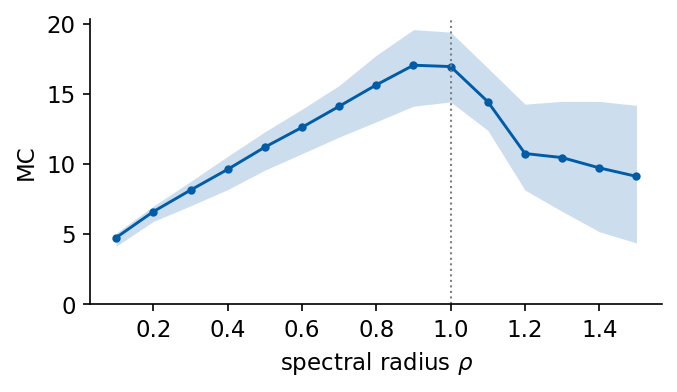

In [16]:
RHO_MC = np.round(np.arange(0.1, 1.51, 0.1), 2)
mc_grid = np.array([[memory_capacity(r_, seed=sd).sum() for sd in (0, 1, 2)] for r_ in RHO_MC])
i_best = int(np.argmax(mc_grid.mean(1)))
nums["mc_vs_rho"] = dict(rho=RHO_MC.tolist(), mean=mc_grid.mean(1).tolist(), min=mc_grid.min(1).tolist(),
                         max=mc_grid.max(1).tolist(), rho_best=float(RHO_MC[i_best]), mc_best=float(mc_grid.mean(1)[i_best]))
for r_, row in zip(RHO_MC, mc_grid):
    print(f"rho = {r_:4.2f}: MC over 3 reservoirs = " + ", ".join(f"{v:5.1f}" for v in row))
print(f"largest mean MC {mc_grid.mean(1)[i_best]:.1f} at rho = {RHO_MC[i_best]}")
with mpl.rc_context(SLIDE_RC):
    fig, ax = plt.subplots(figsize=(4.4, 2.5), layout="constrained")
    ax.fill_between(RHO_MC, mc_grid.min(1), mc_grid.max(1), color=UJBlue, alpha=0.2, lw=0)
    ax.plot(RHO_MC, mc_grid.mean(1), "o-", ms=3, color=UJBlue)
    ax.axvline(1.0, color="0.5", ls=":", lw=1.0)
    ax.set_xlabel(r"spectral radius $\rho$"); ax.set_ylabel("MC"); ax.set_ylim(0, None)
    save(fig, "fig_lab046_mc_rho"); plt.show()

The mean capacity grows with $\rho$ to a maximum of 17.0 at $\rho=0.9$ and decreases beyond $\rho=1$. Above $\rho=1$ the three reservoirs behave differently, with a spread from 4.4 to 14.2 at $\rho=1.5$, so the position and height of the maximum are statements about these reservoirs with $N=50$ only. For linear recall from a white-noise input the largest mean capacity in this test lies just below $\rho=1$, where the relaxation is slowest while the two copies of the reservoir still converge.

<hr/>
## 7. NARMA benchmark

A useful reservoir needs nonlinearity as well as memory. The NARMA task of order $n$ asks for both together [A. F. Atiya, A. G. Parlos, IEEE Trans. Neural Netw. **11**, 697 (2000), [doi:10.1109/72.846741](https://doi.org/10.1109/72.846741)]. An input $u_k$ uniform in $[0,0.5]$ drives the system
$$y_k=0.3\,y_{k-1}+0.05\,y_{k-1}\sum_{i=1}^{n}y_{k-i}+1.5\,u_{k-n}u_{k-1}+0.1 ,$$
and the model, which sees only $u$, must return $y_{k+1}$ at time $k$. The product $u_{k-n}u_{k-1}$ needs a memory of $n$ steps and a multiplication, and the feedback through $y$ adds a dependence on older inputs.

ReservoirPy contains a NARMA generator, `reservoirpy.datasets.narma`. Its sum runs over $y_{k-2},\dots,y_{k-n-1}$ and its product is $u_{k-n-1}u_{k-1}$, shifted by one step from the formula above. Our generator takes the first lag of the sum and the lag of the product as arguments and reproduces the library series with the shifted values. We compare three models trained on the same data, a linear readout of the last 20 inputs, a quadratic readout (NVAR) of the last 12 inputs, and an ESN with $N=100$ units whose $\rho$, $\sigma_{\rm in}$ and $\beta$ are chosen on validation data. The score is the NMSE on 1000 test steps after 2500 fitting and 500 validation steps.

In [17]:
@partial(jax.jit, static_argnums=(1, 2, 3))
def narma(u, n, i0=1, m=None):
    # y_k = 0.3 y_{k-1} + 0.05 y_{k-1} sum_{i=i0}^{i0+n-1} y_{k-i} + 1.5 u_{k-m} u_{k-1} + 0.1, y = 0 before k = n+1
    m = n if m is None else m
    def body(k, y):
        window = jax.lax.dynamic_slice(y, (k - i0 - n + 1,), (n,))      # y_{k-i0-n+1}, ..., y_{k-i0}
        return y.at[k].set(0.3 * y[k - 1] + 0.05 * y[k - 1] * window.sum() + 1.5 * u[k - m] * u[k - 1] + 0.1)
    return jax.lax.fori_loop(n + 1, u.shape[0], body, jnp.zeros_like(u))

u_chk = np.random.default_rng(7).uniform(0, 0.5, 1010)
_, y_rpy = rpy_narma(n_timesteps=1000, order=10, a1=0.3, a2=0.05, b=1.5, c=0.1, u=u_chk[:, None])
y_ours = np.asarray(narma(jnp.asarray(u_chk), 10, 2, 11))[10:]
print(f"NARMA-10, library index convention: max |y_JAX - y_ReservoirPy| = {np.abs(y_ours - y_rpy[:, 0]).max():.1e}")

def delay_features(s, ks, p):
    # rows (s_k, s_{k-1}, ..., s_{k-p+1})
    return s[ks[:, None] - np.arange(p)[None, :]]

def nvar_features(s, ks, p):
    # delay vector and all quadratic monomials s_{k-i} s_{k-j}, i <= j
    d = delay_features(s, ks, p)
    iu, ju = np.triu_indices(p)
    return np.concatenate([d, d[:, iu] * d[:, ju]], axis=1)

N_WASH_N, N_FIT_N, N_VAL_N, N_TEST_N = 200, 2500, 500, 1000
u_n = np.random.default_rng(11).uniform(0, 0.5, N_WASH_N + N_FIT_N + N_VAL_N + N_TEST_N + 1)
k_all = np.arange(N_WASH_N, len(u_n) - 1)                         # forecast times k, target y_{k+1}
k_fit, k_val, k_test = np.split(k_all, [N_FIT_N, N_FIT_N + N_VAL_N])

def nmse(pred, true):
    return float(np.mean((pred - true) ** 2) / np.var(true))

def fit_select(F, y, betas=(1e-8, 1e-6, 1e-4, 1e-2)):
    # ridge on rows k_fit, beta chosen on k_val; returns (validation NMSE, test NMSE, test prediction)
    best = (np.inf, None, None)
    for beta in betas:
        W_, b_ = ridge_fit(F[k_fit], y[k_fit + 1, None], beta)
        e = nmse(np.asarray(F[k_val] @ W_ + b_)[:, 0], y[k_val + 1])
        if e < best[0]:
            p = np.asarray(F[k_test] @ W_ + b_)[:, 0]
            best = (e, nmse(p, y[k_test + 1]), p)
    return best

W_n, w_n = esn_base(100, seed=2)
narma_tab, narma_pred = {}, {}
for n in (2, 5, 10):
    y = np.asarray(narma(jnp.asarray(u_n), n))
    assert np.isfinite(y).all()
    lin = delay_features(u_n, np.arange(len(u_n)).clip(19), 20)        # (u_k, ..., u_{k-19}); rows k < 19 unused
    quad = nvar_features(u_n, np.arange(len(u_n)).clip(11), 12)
    f_lin, f_quad = fit_select(lin, y), fit_select(quad, y)
    row = {"linear": f_lin[1], "NVAR": f_quad[1]}
    best_esn = (np.inf, None, None, None)
    for rho_ in (0.5, 0.8, 0.95):
        for si in (0.1, 0.5, 1.0):
            X = np.asarray(esn_states(rho_ * W_n, si * w_n, u_n, 1.0, jnp.zeros(100)))
            e_val, e_test, p = fit_select(X, y)
            if e_val < best_esn[0]:
                best_esn = (e_val, e_test, (rho_, si), p)
    row["ESN"] = best_esn[1]
    narma_tab[n] = row
    narma_pred[n] = dict(y=y[k_test + 1], linear=f_lin[2], NVAR=f_quad[2], ESN=best_esn[3])
    print(f"NARMA-{n:<2d} test NMSE: linear (20 inputs) {row['linear']:.2e} | NVAR (12 inputs) {row['NVAR']:.2e}"
          f" | ESN (N = 100) {row['ESN']:.2e}   (ESN rho = {best_esn[2][0]}, sigma_in = {best_esn[2][1]})")
nums["narma_nmse"] = {f"n{n}": v for n, v in narma_tab.items()}

NARMA-10, library index convention: max |y_JAX - y_ReservoirPy| = 1.1e-16


NARMA-2  test NMSE: linear (20 inputs) 1.05e-01 | NVAR (12 inputs) 3.89e-05 | ESN (N = 100) 2.42e-04   (ESN rho = 0.5, sigma_in = 1.0)


NARMA-5  test NMSE: linear (20 inputs) 1.29e-01 | NVAR (12 inputs) 3.07e-04 | ESN (N = 100) 5.55e-03   (ESN rho = 0.5, sigma_in = 1.0)


NARMA-10 test NMSE: linear (20 inputs) 1.48e-01 | NVAR (12 inputs) 1.00e-01 | ESN (N = 100) 9.44e-02   (ESN rho = 0.95, sigma_in = 0.5)


| test NMSE | linear, 20 inputs | NVAR, 12 inputs | ESN, $N=100$ |
|---|---|---|---|
| NARMA-2 | 0.105 | $3.9\times10^{-5}$ | $2.4\times10^{-4}$ |
| NARMA-5 | 0.129 | $3.1\times10^{-4}$ | $5.6\times10^{-3}$ |
| NARMA-10 | 0.148 | 0.100 | 0.094 |

The linear readout leaves an error between 0.105 and 0.148 for all three orders, since the product $u_{k-n}u_{k-1}$ is not a linear function of the inputs. NVAR contains this product among its features and is close to exact for $n=2$ and $n=5$. For $n=10$ its error grows to 0.100, because the feedback through $y$ brings in older inputs and higher powers. The ESN sees only its 100 state variables and reaches $2.4\times10^{-4}$, $5.6\times10^{-3}$ and 0.094. The reservoir supplies memory and products of the inputs, and its error grows with the order. The figure compares the target with the linear and ESN predictions on 120 test steps of NARMA-10.

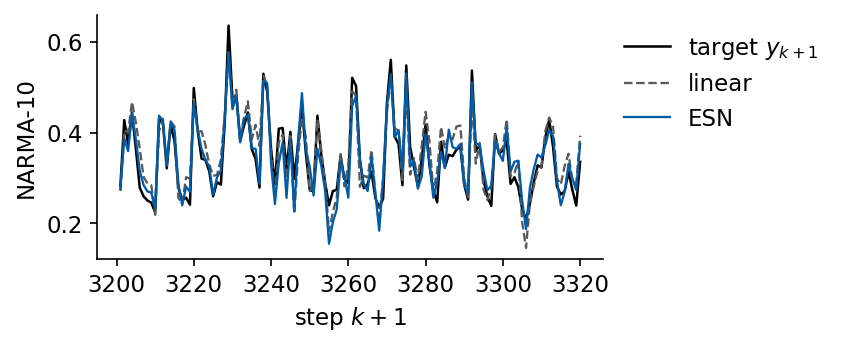

In [18]:
with mpl.rc_context(SLIDE_RC):
    fig, ax = plt.subplots(figsize=(5.5, 2.2), layout="constrained")
    kk = k_test[:120] + 1
    d10 = narma_pred[10]
    ax.plot(kk, d10["y"][:120], color="k", lw=1.2, label="target $y_{k+1}$")
    ax.plot(kk, d10["linear"][:120], color=STYLE["AR"]["color"], ls="--", lw=1.1, label="linear")
    ax.plot(kk, d10["ESN"][:120], color=UJBlue, lw=1.1, label="ESN")
    ax.set_xlabel("step $k+1$"); ax.set_ylabel("NARMA-10")
    ax.legend(loc="upper left", bbox_to_anchor=(1.0, 1.0))
    save(fig, "fig_lab046_narma"); plt.show()

<hr/>
## 8. Forecasting with the echo state network

### Baselines

Persistence repeats the last value, $\hat s_{k+\tau}=s_k$. The direct AR model of order $p$ and the NVAR model are ridge regressions on features of the delay vector $\mathbf d_k=(s_k,s_{k-1},\dots,s_{k-p+1})$,
$$\hat{\mathbf y}_k=W^\top\boldsymbol\phi(\mathbf d_k)+\mathbf b,\qquad \boldsymbol\phi_{\rm AR}=\mathbf d_k,\qquad \boldsymbol\phi_{\rm NVAR}=\big(\mathbf d_k,\ \{s_{k-i}s_{k-j}\}_{0\le i\le j<p}\big),$$
where NVAR has $p+p(p+1)/2$ features [D. J. Gauthier, E. Bollt, A. Griffith, W. A. S. Barbosa, Nat. Commun. **12**, 5564 (2021), [doi:10.1038/s41467-021-25801-2](https://doi.org/10.1038/s41467-021-25801-2)]. The order $p$ and the ridge strength $\beta$ are chosen by the largest $C_{\rm tot}$ on the validation origins.

In [19]:
GRID_BETA = (1e-8, 1e-6, 1e-4, 1e-2, 1.0)
GRID_P = {"AR": (4, 8, 16, 24, 32, 48, 64), "NVAR": (2, 4, 8, 12, 16, 24, 32)}
FEATS = {"AR": delay_features, "NVAR": nvar_features}

def ridge_model(s, kind):
    # choose (p, beta) by validation C_tot, return the test predictions and the chosen setting
    Yf, Yv, Yt = targets(s, K_FIT), targets(s, K_VAL), targets(s, K_TEST)
    best = (-1.0, None, None)
    for p in GRID_P[kind]:
        Ff, Fv = FEATS[kind](s, K_FIT, p), FEATS[kind](s, K_VAL, p)
        for beta in GRID_BETA:
            W, b = ridge_fit(Ff, Yf, beta)
            ctot = score(Fv @ W + b, Yv)["Ctot"]
            if ctot > best[0]:
                best = (ctot, p, beta)
    _, p, beta = best
    Ff, Ft = FEATS[kind](s, K_FIT, p), FEATS[kind](s, K_TEST, p)
    ts = []
    for _ in range(5):                                  # median wall time of one fit
        t0 = time.perf_counter(); W, b = ridge_fit(Ff, Yf, beta); W.block_until_ready(); ts.append(time.perf_counter() - t0)
    return dict(pred=np.asarray(Ft @ W + b), p=p, beta=beta, n_feat=Ff.shape[1], t_fit=float(np.median(ts)),
                **score(Ft @ W + b, Yt))

res = {name: {} for name in SIGNALS}       # res[signal][model] = scores and predictions on the test origins
for name in SIGNALS:
    s = sig[name]
    Yt = targets(s, K_TEST)
    P_pers = np.repeat(s[K_TEST][:, None], TAU_MAX, 1)
    res[name]["persistence"] = dict(pred=P_pers, **score(P_pers, Yt))
    for kind in ("AR", "NVAR"):
        res[name][kind] = ridge_model(s, kind)
    print(f"{name:8s} C_tot: persistence {res[name]['persistence']['Ctot']:5.1f} | "
          + " | ".join(f"{k} {res[name][k]['Ctot']:5.1f} (p={res[name][k]['p']}, beta={res[name][k]['beta']:.0e})"
                       for k in ("AR", "NVAR")))

Lorenz   C_tot: persistence   8.4 | AR  15.4 (p=16, beta=1e-08) | NVAR  15.4 (p=16, beta=1e-08)


MG15     C_tot: persistence  19.5 | AR  49.8 (p=64, beta=1e-08) | NVAR  50.0 (p=32, beta=1e-08)


MG25     C_tot: persistence  13.3 | AR  33.1 (p=64, beta=1e-08) | NVAR  45.5 (p=32, beta=1e-08)


MG35     C_tot: persistence  11.8 | AR  38.0 (p=64, beta=1e-08) | NVAR  48.6 (p=32, beta=1e-08)


SantaFe  C_tot: persistence   5.5 | AR  16.5 (p=64, beta=1e+00) | NVAR  34.7 (p=32, beta=1e-02)


### Echo state network forecaster

The forecasting reservoir has $N=300$ units and is driven by the rescaled signal from the first sample on, so its state at the first fitting origin $k=63$ has seen the 64 values $s_0,\dots,s_{63}$. The readout maps $\mathbf r_k$ to all 50 horizons. The spectral radius $\rho\in\{0.5,0.8,0.95,1.1\}$, the input scaling $\sigma_{\rm in}\in\{0.1,0.5,1\}$, the leak rate $\alpha\in\{0.3,1\}$ and the ridge strength $\beta\in\{10^{-8},10^{-6},10^{-4},10^{-2}\}$ are chosen by the validation $C_{\rm tot}$. One fixed random reservoir, the one drawn above with seed 0, is used for all signals. Each setting costs one run of the reservoir and one linear solve per ridge strength.

In [20]:
N_ESN = 300
W_esn, w_esn = W300, w300                                           # the reservoir of seed 0 drawn above
ESN_GRID = [(r, si, a) for r in (0.5, 0.8, 0.95, 1.1) for si in (0.1, 0.5, 1.0) for a in (0.3, 1.0)]
ESN_BETA = (1e-8, 1e-6, 1e-4, 1e-2)

def esn_select(s, W, w, grid=ESN_GRID, betas=ESN_BETA):
    # validation C_tot for every reservoir setting and ridge strength; returns the best (C_tot, setting)
    Yf, Yv = targets(s, K_FIT), targets(s, K_VAL)
    best = (-1.0, None)
    for (r, si, a) in grid:
        X = esn_states(r * W, si * w, s, a, jnp.zeros(W.shape[0]))
        for beta in betas:
            Wo, b = ridge_fit(X[K_FIT], Yf, beta)
            ctot = score(X[K_VAL] @ Wo + b, Yv)["Ctot"]
            if ctot > best[0]:
                best = (ctot, (r, si, a, beta))
    return best

def esn_fit(s, W, w, setting):
    # one fit at a fixed setting: reservoir run and ridge solve, timed; scores on the test origins
    r, si, a, beta = setting
    ts = []
    for _ in range(5):
        t0 = time.perf_counter()
        X = esn_states(r * W, si * w, s, a, jnp.zeros(W.shape[0]))
        Wo, b = ridge_fit(X[K_FIT], targets(s, K_FIT), beta); Wo.block_until_ready()
        ts.append(time.perf_counter() - t0)
    X = np.asarray(X)
    P = np.asarray(X[K_TEST] @ Wo + b)
    return dict(pred=P, rho=r, sigma_in=si, alpha=a, beta=beta, t_fit=float(np.median(ts)), W_out=np.asarray(Wo),
                b=np.asarray(b), X=X, **score(P, targets(s, K_TEST)))

t0 = time.time()
for name in SIGNALS:
    val_ctot, setting = esn_select(sig[name], W_esn, w_esn)
    res[name]["ESN"] = esn_fit(sig[name], W_esn, w_esn, setting)
    res[name]["ESN"]["val_Ctot"] = val_ctot
    e = res[name]["ESN"]
    print(f"{name:8s} ESN C_tot = {e['Ctot']:5.1f} (validation {val_ctot:5.1f}; rho = {e['rho']}, sigma_in = {e['sigma_in']},"
          f" alpha = {e['alpha']}, beta = {e['beta']:.0e})")
t_search = time.time() - t0
nums["esn_search_time_s"] = t_search
print(f"search over {len(ESN_GRID)} reservoirs x {len(ESN_BETA)} ridge strengths for 5 signals: {t_search:.0f} s")

Lorenz   ESN C_tot =  39.2 (validation  42.2; rho = 1.1, sigma_in = 1.0, alpha = 1.0, beta = 1e-08)


MG15     ESN C_tot =  50.0 (validation  50.0; rho = 1.1, sigma_in = 0.5, alpha = 1.0, beta = 1e-08)


MG25     ESN C_tot =  48.3 (validation  49.4; rho = 0.95, sigma_in = 1.0, alpha = 0.3, beta = 1e-08)


MG35     ESN C_tot =  49.8 (validation  49.5; rho = 0.8, sigma_in = 1.0, alpha = 0.3, beta = 1e-08)


SantaFe  ESN C_tot =  34.7 (validation  36.5; rho = 0.95, sigma_in = 0.1, alpha = 1.0, beta = 1e-08)
search over 24 reservoirs x 4 ridge strengths for 5 signals: 23 s


The whole search over 24 reservoir settings and 4 ridge strengths for five signals took 23 s. As an independent check we repeat the search with reservoirs drawn by ReservoirPy itself, `Reservoir(units=300, sr=rho, lr=alpha, input_scaling=sigma_in, seed=0)`. The library draws its own sparse Gaussian $W$ and gives only 10% of the units an input weight, $\pm\sigma_{\rm in}$, so the two reservoirs are different random systems of the same kind.

In [21]:
def rpy_states(s, r, si, a, seed=0, N=N_ESN):
    # a fresh ReservoirPy reservoir with its own random W (normal, 10% nonzero) and W_in (+-sigma_in, 10% nonzero)
    R = Reservoir(units=N, sr=r, lr=a, input_scaling=si, seed=seed)
    return R.run(s[:, None])

rpy_ctot = {}
t0 = time.time()
for name in SIGNALS:
    s = sig[name]; Yf, Yv = targets(s, K_FIT), targets(s, K_VAL)
    best = (-1.0, None, None)
    for (r, si, a) in ESN_GRID:
        X = rpy_states(s, r, si, a)
        for beta in ESN_BETA:
            Wo, b = ridge_fit(X[K_FIT], Yf, beta)
            v = score(X[K_VAL] @ Wo + b, Yv)["Ctot"]
            if v > best[0]:
                best = (v, X[K_TEST] @ Wo + b, (r, si, a, beta))
    rpy_ctot[name] = score(best[1], targets(s, K_TEST))["Ctot"]
    print(f"{name:8s} ReservoirPy reservoir: test C_tot = {rpy_ctot[name]:5.1f} (rho, sigma_in, alpha, beta = {best[2]})"
          f" | JAX reservoir: {res[name]['ESN']['Ctot']:5.1f}")
nums["rpy_own_Ctot"] = rpy_ctot
print(f"{time.time() - t0:.0f} s")

Lorenz   ReservoirPy reservoir: test C_tot =  36.8 (rho, sigma_in, alpha, beta = (0.95, 1.0, 1.0, 1e-08)) | JAX reservoir:  39.2


MG15     ReservoirPy reservoir: test C_tot =  50.0 (rho, sigma_in, alpha, beta = (1.1, 1.0, 1.0, 1e-08)) | JAX reservoir:  50.0


MG25     ReservoirPy reservoir: test C_tot =  48.7 (rho, sigma_in, alpha, beta = (0.95, 0.5, 1.0, 1e-08)) | JAX reservoir:  48.3


MG35     ReservoirPy reservoir: test C_tot =  49.8 (rho, sigma_in, alpha, beta = (0.8, 1.0, 0.3, 1e-08)) | JAX reservoir:  49.8


SantaFe  ReservoirPy reservoir: test C_tot =  33.3 (rho, sigma_in, alpha, beta = (1.1, 1.0, 1.0, 0.0001)) | JAX reservoir:  34.7
74 s


The library reservoirs reach test values within 2.5 of ours on every signal. The validation search selected $\rho=1.1$ for Lorenz and for Mackey–Glass at $\tau_{\rm MG}=15$, above the usual rule $\rho<1$. We therefore test the echo state property at every selected setting with the actual input, from two random starts of the 300-unit reservoir, and we refit every selected ESN with a washout of 263 steps, the fitting origins $k=263,\dots,2449$.

In [22]:
nums["esp_selected"] = {}
K_FIT_LONG = K_FIT[K_FIT >= 263]                                     # washout of 263 steps
for name in SIGNALS:
    e = res[name]["ESN"]
    rng = np.random.default_rng(5)
    xa, xb = rng.uniform(-1, 1, N_ESN), rng.uniform(-1, 1, N_ESN)
    Xa = esn_states(e["rho"] * W_esn, e["sigma_in"] * w_esn, sig[name], e["alpha"], xa)
    Xb = esn_states(e["rho"] * W_esn, e["sigma_in"] * w_esn, sig[name], e["alpha"], xb)
    d = np.linalg.norm(np.asarray(Xa - Xb), axis=1)
    # the same reservoir run, fitted on the origins 263..2449 only
    Wo, b = ridge_fit(e["X"][K_FIT_LONG], targets(sig[name], K_FIT_LONG), e["beta"])
    c_long = score(e["X"][K_TEST] @ Wo + b, targets(sig[name], K_TEST))["Ctot"]
    k0 = K_FIT[0]
    nums["esp_selected"][name] = dict(d_first_fit=float(d[k0]), d_263=float(d[263]), d_end=float(d[-1]),
                                      d_max_test=float(d[K_TEST].max()), Ctot_washout263=c_long)
    print(f"{name:8s} rho = {e['rho']:4}, alpha = {e['alpha']}: |r_k - r'_k| at k = {k0}: {d[k0]:.1e}, at k = 263:"
          f" {d[263]:.1e}, largest on the test origins: {d[K_TEST].max():.1e} | test C_tot with washout 63:"
          f" {e['Ctot']:5.2f}, with washout 263: {c_long:5.2f}")

Lorenz   rho =  1.1, alpha = 1.0: |r_k - r'_k| at k = 63: 4.5e-03, at k = 263: 2.7e-09, largest on the test origins: 3.9e-15 | test C_tot with washout 63: 39.24, with washout 263: 39.07


MG15     rho =  1.1, alpha = 1.0: |r_k - r'_k| at k = 63: 9.8e-02, at k = 263: 2.0e-06, largest on the test origins: 4.2e-15 | test C_tot with washout 63: 50.00, with washout 263: 50.00


MG25     rho = 0.95, alpha = 0.3: |r_k - r'_k| at k = 63: 1.8e-02, at k = 263: 6.9e-10, largest on the test origins: 1.1e-15 | test C_tot with washout 63: 48.28, with washout 263: 48.23


MG35     rho =  0.8, alpha = 0.3: |r_k - r'_k| at k = 63: 4.4e-03, at k = 263: 3.0e-13, largest on the test origins: 8.8e-16 | test C_tot with washout 63: 49.82, with washout 263: 49.83


SantaFe  rho = 0.95, alpha = 1.0: |r_k - r'_k| at k = 63: 1.9e-02, at k = 263: 4.5e-07, largest on the test origins: 3.7e-16 | test C_tot with washout 63: 34.67, with washout 263: 34.02


At every selected setting the two copies differ by less than $4.2\times10^{-15}$ on the test origins, so for these inputs the state has forgotten its start long before the test block. The strong input ($\sigma_{\rm in}=1.0$ for Lorenz) keeps the reservoir contracting at $\rho=1.1$, in line with the scan of the echo state property. The threshold also depends on the input signal and on the reservoir. On Mackey–Glass at $\tau_{\rm MG}=15$ the 300-unit reservoir contracts at $\rho=1.1$ with $\sigma_{\rm in}=0.5$, while the 100-unit reservoir driven by the Santa Fe signal at the same $\sigma_{\rm in}$ keeps its two copies apart from $\rho=1.1$ on. At the first fitting origin, however, the copies still differ by up to 0.10, on Mackey–Glass at $\tau_{\rm MG}=15$, so the first fitting rows still carry a trace of the start. After 263 steps the largest distance is $2.0\times10^{-6}$. A fit with this longer washout uses 200 fewer fitting rows and changes the test $C_{\rm tot}$ by at most 0.66, on Santa Fe, where it falls to 34.02. For a reservoir whose start is forgotten more slowly, a washout of a few hundred steps is the safer choice.

The figure shows the capacity $C(\tau)=r^2(\hat s_{k+\tau},s_{k+\tau})$ on the test origins for persistence, AR, NVAR and the ESN on every signal.

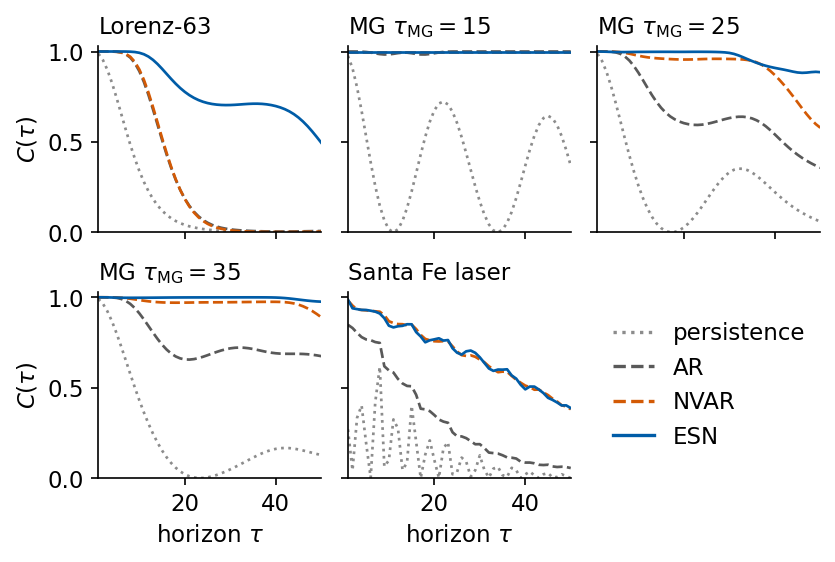

model           Lorenz      MG15      MG25      MG35   SantaFe     (test C_tot, maximum 50)
persistence        8.4      19.5      13.3      11.8       5.5
AR                15.4      49.8      33.1      38.0      16.5
NVAR              15.4      50.0      45.5      48.6      34.7
ESN               39.2      50.0      48.3      49.8      34.7

model           Lorenz      MG15      MG25      MG35   SantaFe     (tau_1/2, '>50' if C stays above 0.5)
persistence          8         6         8        10         1
AR                  16       >50        42       >50        16
NVAR                16       >50       >50       >50        42
ESN                 50       >50       >50       >50        40

ESN - NVAR: Lorenz +23.88, MG15 -0.00, MG25 +2.77, MG35 +1.22, SantaFe -0.04


In [23]:
MODELS_HERE = ("persistence", "AR", "NVAR", "ESN")
with mpl.rc_context(SLIDE_RC):
    fig, axs = plt.subplots(2, 3, figsize=(5.5, 3.6), sharex=True, sharey=True)
    fig.subplots_adjust(left=0.11, right=0.985, bottom=0.13, top=0.93, wspace=0.12, hspace=0.32)
    for ax, name in zip(axs.ravel(), SIGNALS):
        for m in MODELS_HERE:
            ax.plot(TAUS, res[name][m]["C"], lw=1.3, label=m, **STYLE[m])
        ax.set_title(LABEL[name], loc="left", fontsize=11)
        ax.set_ylim(0, 1.03); ax.set_xlim(1, TAU_MAX)
    for ax in axs[1]: ax.set_xlabel(r"horizon $\tau$")
    for ax in axs[:, 0]: ax.set_ylabel(r"$C(\tau)$")
    axs[1, 2].axis("off")
    model_legend(axs[1, 2], MODELS_HERE, loc="center", handlelength=1.8)
    save(fig, "fig_lab046_capacity"); plt.show()

print(f"{'model':12s}" + "".join(f"{n:>10s}" for n in SIGNALS) + "     (test C_tot, maximum 50)")
for m in MODELS_HERE:
    print(f"{m:12s}" + "".join(f"{res[n][m]['Ctot']:10.1f}" for n in SIGNALS))
print(f"\n{'model':12s}" + "".join(f"{n:>10s}" for n in SIGNALS) + "     (tau_1/2, '>50' if C stays above 0.5)")
for m in MODELS_HERE:
    print(f"{m:12s}" + "".join(f"{(res[n][m]['tau_half'] or '>50'):>10}" for n in SIGNALS))
print("\nESN - NVAR: " + ", ".join(f"{n} {res[n]['ESN']['Ctot'] - res[n]['NVAR']['Ctot']:+.2f}" for n in SIGNALS))
nums["Ctot"] = {n: {m: res[n][m]["Ctot"] for m in MODELS_HERE} for n in SIGNALS}
nums["tau_half"] = {n: {m: res[n][m]["tau_half"] for m in MODELS_HERE} for n in SIGNALS}
nums["ridge_choice"] = {n: {m: dict(p=res[n][m]["p"], beta=res[n][m]["beta"], n_feat=res[n][m]["n_feat"])
                            for m in ("AR", "NVAR")} for n in SIGNALS}
nums["esn_choice"] = {n: {k: res[n]["ESN"][k] for k in ("rho", "sigma_in", "alpha", "beta", "val_Ctot")} for n in SIGNALS}

| test $C_{\rm tot}$ | Lorenz | MG 15 | MG 25 | MG 35 | Santa Fe |
|---|---|---|---|---|---|
| persistence | 8.4 | 19.5 | 13.3 | 11.8 | 5.5 |
| AR | 15.4 | 49.8 | 33.1 | 38.0 | 16.5 |
| NVAR | 15.4 | 50.0 | 45.5 | 48.6 | 34.7 |
| ESN, $N=300$ | 39.2 | 50.0 | 48.3 | 49.8 | 34.7 |

The ESN gives the largest $C_{\rm tot}$ of these models on Lorenz, 39.2 against 15.4 for AR and NVAR, and its capacity falls below 0.5 only at horizon 50. On the Mackey–Glass signals at 25 and 35 it is ahead of NVAR by 2.8 and 1.2, and at 15 all models except persistence reach the maximum. On Santa Fe the ESN and NVAR differ by 0.04, a tie for this one random reservoir.

One step ahead, the upper panels compare the target $s_{k+1}$ (black) with the ESN forecast $\hat s_{k+1}$ (dashed) on the first 100 test targets, and the lower panels show $\hat s_{k+1}$ against $s_{k+1}$ on all test targets with the capacity $C$ at $\tau=1$.

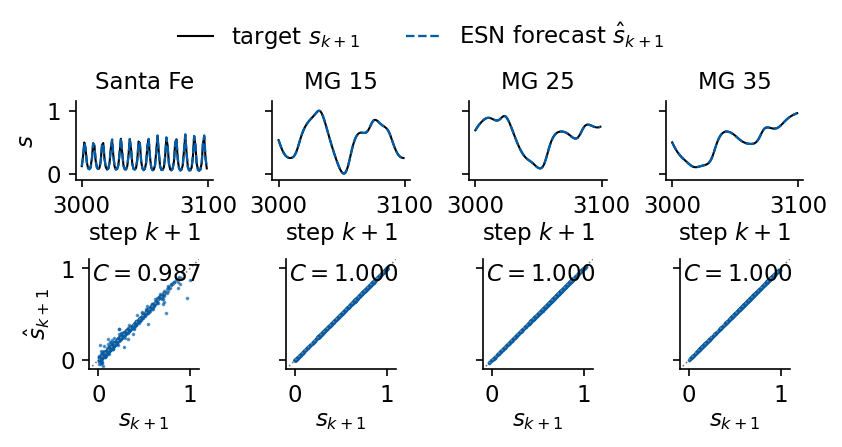

Lorenz   one step ahead: C = 1.0000, NMSE = 2.1e-10
MG15     one step ahead: C = 1.0000, NMSE = 1.7e-10
MG25     one step ahead: C = 0.9999, NMSE = 6.2e-05
MG35     one step ahead: C = 1.0000, NMSE = 2.3e-05
SantaFe  one step ahead: C = 0.9870, NMSE = 1.3e-02


In [24]:
OS_SIG = ["SantaFe", "MG15", "MG25", "MG35"]
OS_TITLE = {"SantaFe": "Santa Fe", "MG15": "MG 15", "MG25": "MG 25", "MG35": "MG 35"}
K_SHOW = 100
nums["one_step"] = {}
for name in SIGNALS:
    y_t = targets(sig[name], K_TEST)[:, 0]; y_p = res[name]["ESN"]["pred"][:, 0]
    nums["one_step"][name] = dict(C=float(np.corrcoef(y_p, y_t)[0, 1] ** 2),
                                  nmse=float(np.sum((y_t - y_p) ** 2) / np.sum((y_t - y_t.mean()) ** 2)))
with mpl.rc_context(SLIDE_RC):
    fig, axs = plt.subplots(2, 4, figsize=(5.5, 2.9), layout="constrained", gridspec_kw={"height_ratios": [1.0, 1.4]})
    for c_, name in enumerate(OS_SIG):
        a_t, a_s = axs[0, c_], axs[1, c_]
        y_t = targets(sig[name], K_TEST)[:, 0]; y_p = res[name]["ESN"]["pred"][:, 0]
        kk = K_TEST[:K_SHOW] + 1
        a_t.plot(kk, y_t[:K_SHOW], color="k", lw=1.0, label="target $s_{k+1}$")
        a_t.plot(kk, y_p[:K_SHOW], "--", color=UJBlue, lw=1.1, label=r"ESN forecast $\hat s_{k+1}$")
        a_t.set_title(OS_TITLE[name]); a_t.set_ylim(-0.1, 1.15); a_t.set_yticks([0, 1])
        a_t.set_xticks([kk[0], kk[0] + 100]); a_t.set_xlabel("step $k+1$", labelpad=1)
        a_s.plot(y_t, y_p, ".", ms=1.5, color=UJBlue, alpha=0.6)
        a_s.plot([-0.1, 1.1], [-0.1, 1.1], color="0.5", lw=0.8, ls=":")
        a_s.set_xlim(-0.1, 1.1); a_s.set_ylim(-0.1, 1.1); a_s.set_aspect("equal")
        a_s.set_xticks([0, 1]); a_s.set_yticks([0, 1]); a_s.set_xlabel("$s_{k+1}$", labelpad=1)
        a_s.text(0.03, 0.97, f"$C={nums['one_step'][name]['C']:.3f}$", transform=a_s.transAxes, va="top", ha="left")
        if c_ > 0:
            a_t.set_yticklabels([]); a_s.set_yticklabels([])
    axs[0, 0].set_ylabel("$s$"); axs[1, 0].set_ylabel(r"$\hat s_{k+1}$")
    fig.legend(*axs[0, 0].get_legend_handles_labels(), loc="outside upper center", ncol=2, handlelength=1.5)
    save(fig, "fig_lab046_onestep"); plt.show()
for name in SIGNALS:
    print(f"{name:8s} one step ahead: C = {nums['one_step'][name]['C']:.4f}, NMSE = {nums['one_step'][name]['nmse']:.1e}")

The one-step forecasts of the Mackey–Glass signals lie on the diagonal, with $C$ at least 0.9999. Santa Fe reaches $C=0.987$, and the visible scatter comes from the largest pulses and the collapses.

### Random reservoirs

All numbers so far come from one random reservoir. Five reservoirs drawn with different seeds, at the settings selected for seed 0, give the spread below.

In [25]:
SEEDS = (0, 1, 2, 3, 4)
nums["seed_Ctot"] = {}
for name in SIGNALS:
    e = res[name]["ESN"]; setting = (e["rho"], e["sigma_in"], e["alpha"], e["beta"])
    vals = []
    for sd in SEEDS:
        W_, w_ = esn_base(N_ESN, seed=sd)
        r, si, a, beta = setting
        X = esn_states(r * W_, si * w_, sig[name], a, jnp.zeros(N_ESN))
        Wo, b = ridge_fit(X[K_FIT], targets(sig[name], K_FIT), beta)
        vals.append(score(X[K_TEST] @ Wo + b, targets(sig[name], K_TEST))["Ctot"])
    nums["seed_Ctot"][name] = vals
    nums.setdefault("seed_spread", {})[name] = float(max(vals) - min(vals))
    print(f"{name:8s} test C_tot for reservoir seeds {SEEDS}: " + ", ".join(f"{v:5.1f}" for v in vals)
          + f" | spread {max(vals) - min(vals):.2f} | NVAR {res[name]['NVAR']['Ctot']:5.1f}, seeds below NVAR: {sum(v < res[name]['NVAR']['Ctot'] - 0.05 for v in vals)}")
sf = nums["seed_Ctot"]["SantaFe"]; nv = res["SantaFe"]["NVAR"]["Ctot"]
print("Santa Fe, seeds 1-4: below seed 0 by " + ", ".join(f"{sf[0] - v:.2f}" for v in sf[1:])
      + " | below NVAR by " + ", ".join(f"{nv - v:.2f}" for v in sf[1:]))

Lorenz   test C_tot for reservoir seeds (0, 1, 2, 3, 4):  39.2,  39.4,  39.0,  39.4,  40.0 | spread 1.01 | NVAR  15.4, seeds below NVAR: 0


MG15     test C_tot for reservoir seeds (0, 1, 2, 3, 4):  50.0,  50.0,  50.0,  50.0,  50.0 | spread 0.00 | NVAR  50.0, seeds below NVAR: 0


MG25     test C_tot for reservoir seeds (0, 1, 2, 3, 4):  48.3,  47.8,  47.5,  47.4,  48.3 | spread 0.96 | NVAR  45.5, seeds below NVAR: 0


MG35     test C_tot for reservoir seeds (0, 1, 2, 3, 4):  49.8,  49.8,  49.9,  49.8,  49.8 | spread 0.05 | NVAR  48.6, seeds below NVAR: 0


SantaFe  test C_tot for reservoir seeds (0, 1, 2, 3, 4):  34.7,  32.3,  33.3,  31.9,  31.5 | spread 3.13 | NVAR  34.7, seeds below NVAR: 4
Santa Fe, seeds 1-4: below seed 0 by 2.41, 1.40, 2.82, 3.13 | below NVAR by 2.45, 1.44, 2.86, 3.17


The spread over seeds is 1.0 on Lorenz and 3.1 on Santa Fe, where seed 0 happens to be the best of the five. On Santa Fe the other four reservoirs reach 31.5 to 33.3, all below the 34.7 of NVAR, so the tie with NVAR holds for seed 0 only. On Lorenz and on Mackey–Glass at 25 and 35 every seed stays above NVAR, with the smallest margin 1.2. Differences between models smaller than about 3 units of $C_{\rm tot}$ on Santa Fe are within the variation between random reservoirs.

### Reservoir size and spectral radius

The last scan varies the number of units $N\in\{50,100,200,300,500\}$ and the spectral radius on a grid that extends to $\rho=1.25$, with $\sigma_{\rm in}$ and $\alpha$ fixed at the values selected for each signal and $\beta$ chosen as before. The heat maps show the validation $C_{\rm tot}$ for Lorenz and Santa Fe, so the test block plays no role here.

Lorenz   best validation C_tot  43.0 at N = 500, rho = 1.1 | N = 50:  37.5, N = 500:  43.0


MG15     best validation C_tot  50.0 at N = 500, rho = 1.1 | N = 50:  50.0, N = 500:  50.0


MG25     best validation C_tot  49.5 at N = 500, rho = 0.95 | N = 50:  48.5, N = 500:  49.5


MG35     best validation C_tot  49.5 at N = 500, rho = 0.8 | N = 50:  48.6, N = 500:  49.5


SantaFe  best validation C_tot  40.1 at N = 500, rho = 0.95 | N = 50:  23.4, N = 500:  40.1
scan time 23 s
Lorenz: validation C_tot, rows N = (50, 100, 200, 300, 500), columns rho = (0.5, 0.8, 0.95, 1.1, 1.25)
  N =  50:  35.8   36.9   36.7   37.3   37.5
  N = 100:  36.1   37.7   38.5   36.7   16.4
  N = 200:  36.8   38.7   40.4   41.1   34.3
  N = 300:  36.8   39.3   41.0   42.2   40.5
  N = 500:  36.9   39.6   41.3   43.0   26.7
SantaFe: validation C_tot, rows N = (50, 100, 200, 300, 500), columns rho = (0.5, 0.8, 0.95, 1.1, 1.25)
  N =  50:  18.0   20.5   20.4   20.8   23.4
  N = 100:  20.0   27.4   27.5   17.1   13.4
  N = 200:  20.6   28.4   35.3   12.9   14.5
  N = 300:  20.7   28.4   36.5   15.7   12.6
  N = 500:  21.1   31.6   40.1   17.9   10.2


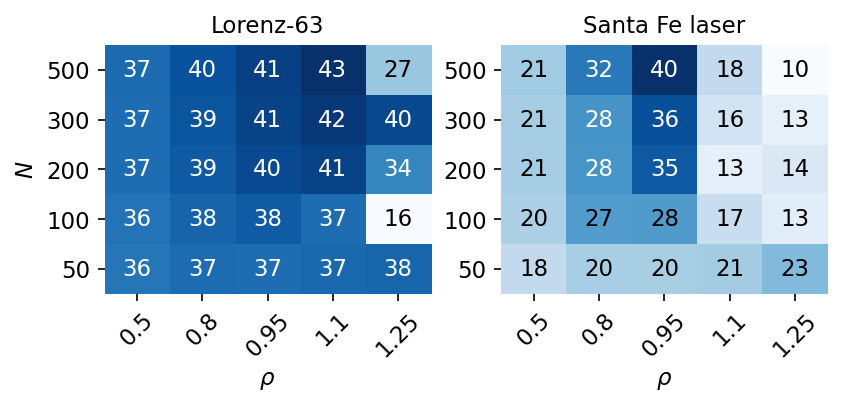

In [26]:
NS_SCAN = (50, 100, 200, 300, 500)
RHO_GRID = (0.5, 0.8, 0.95, 1.1, 1.25)
scan = {}
t0 = time.time()
bases = {N: esn_base(N, seed=0) for N in NS_SCAN}
for name in SIGNALS:
    e = res[name]["ESN"]
    scan[name] = np.zeros((len(NS_SCAN), len(RHO_GRID)))
    for i, N in enumerate(NS_SCAN):
        for j, r in enumerate(RHO_GRID):
            scan[name][i, j] = esn_select(sig[name], *bases[N], grid=[(r, e["sigma_in"], e["alpha"])])[0]
    i, j = np.unravel_index(np.argmax(scan[name]), scan[name].shape)
    print(f"{name:8s} best validation C_tot {scan[name][i, j]:5.1f} at N = {NS_SCAN[i]}, rho = {RHO_GRID[j]}"
          f" | N = 50: {scan[name][0].max():5.1f}, N = 500: {scan[name][-1].max():5.1f}")
nums["scan"] = {n: dict(Ns=list(NS_SCAN), rhos=list(RHO_GRID), val_Ctot=scan[n].tolist()) for n in SIGNALS}
print(f"scan time {time.time() - t0:.0f} s")
for name in ("Lorenz", "SantaFe"):
    print(f"{name}: validation C_tot, rows N = {NS_SCAN}, columns rho = {RHO_GRID}")
    for N, row in zip(NS_SCAN, scan[name]):
        print(f"  N = {N:3d}: " + "  ".join(f"{v:5.1f}" for v in row))
with mpl.rc_context(SLIDE_RC):
    fig, axs = plt.subplots(1, 2, figsize=(5.5, 2.6), layout="constrained")
    for ax, name in zip(axs, ("Lorenz", "SantaFe")):
        im = ax.imshow(scan[name], origin="lower", cmap="Blues", aspect="auto")
        for i in range(len(NS_SCAN)):
            for j in range(len(RHO_GRID)):
                v = scan[name][i, j]
                ax.text(j, i, f"{v:.0f}", ha="center", va="center",
                        color="white" if v > scan[name].min() + 0.6 * np.ptp(scan[name]) else "k")
        ax.set_xticks(range(len(RHO_GRID)), [str(r) for r in RHO_GRID], rotation=45)
        ax.set_yticks(range(len(NS_SCAN)), [str(N) for N in NS_SCAN])
        ax.set_xlabel(r"$\rho$"); ax.set_title(LABEL[name])
        ax.spines[:].set_visible(False)
    axs[0].set_ylabel("$N$")
    save(fig, "fig_lab046_scan"); plt.show()

On Santa Fe the best validation capacity grows from 23.4 at $N=50$ to 40.1 at $N=500$. For $N\ge100$ it is largest at $\rho=0.95$ and collapses for $\rho\ge1.1$, to at most 17.9, at the weak input $\sigma_{\rm in}=0.1$ selected for this signal. This agrees with the two-copy scan of the 100-unit reservoir, whose copies stay apart from $\rho=1.0$ on at this input scaling. The reservoir with $N=50$ behaves differently. Its capacity rises with $\rho$ over the whole grid and is largest, 23.4, at $\rho=1.25$, far below the values of the larger reservoirs, and its echo state property was not tested. On Lorenz the dependence on $N$ is weaker, from 37.5 to 43.0, and the strong input $\sigma_{\rm in}=1.0$ keeps good values up to $\rho=1.1$, while at $\rho=1.25$ the capacity drops to 16.4 for $N=100$ and to 26.7 for $N=500$. Larger reservoirs help most where the forecast needs many different nonlinear features of the recent past.

### Choice of $\rho$, $\sigma_{\rm in}$ and $\alpha$

The scans of this notebook suggest a practical order for the three reservoir parameters. The spectral radius is the first one. Values between 0.8 and 1 give the longest memory in the memory-capacity scan, and the echo state property has to be checked with the actual input whenever $\rho$ approaches or exceeds 1, as the two-copy test above does in a few lines. The input scaling sets the strength of the nonlinearity. A small $\sigma_{\rm in}$ keeps the units in the linear part of tanh and suits signals whose forecast needs a fine resolution of the amplitude, like Santa Fe, where the search chose $\sigma_{\rm in}=0.1$. A large one drives the units into saturation, adds nonlinearity and stabilises the reservoir at larger $\rho$, as on Lorenz with $\sigma_{\rm in}=1.0$ at $\rho=1.1$. The leak rate adapts the memory time to the time scale of the signal through the effective decay $(1-\alpha)+\alpha\rho$. The search chose $\alpha=0.3$ for the slowly varying Mackey–Glass signals at 25 and 35 and $\alpha=1$ for the other three. After a coarse grid of this kind on validation data, a larger $N$ is the most reliable further improvement.

<hr/>
## 9. Cost

The ridge models and the ESN are fitted by one run of the features and one linear solve. Fully trained networks need many passes of gradient descent. We load the scores, median fit times and parameter counts of a multilayer perceptron (MLP), an RNN, a gated recurrent unit (GRU) and a long short-term memory network (LSTM), trained in a separate notebook with the same signals, origins and scores, and set them next to the models of this notebook. The fit times are wall-clock times for the selected setting without the hyperparameter search, medians over the five signals, measured in different runs on the same machine. The parameter counts are those of the settings selected for Santa Fe. During the run of this notebook the machine was shared with other jobs, so the times of this notebook are upper estimates. All times change with hardware, load and implementation.

In [27]:
# scores, fit times and parameter counts of trained networks fitted with the same signals, origins and scores
p036 = find_file("numbers_lab036.json", "../../Lecture_8/Notebooks/figures")
trained = json.load(open(p036)) if p036 else None
if trained is None:
    print("numbers of the trained networks not found, the comparison shows the models of this notebook only")
NETS = ("MLP", "RNN", "GRU", "LSTM") if trained else ()
HERE = ("AR", "NVAR", "ESN")
cost = {m: float(np.median([res[n][m]["t_fit"] for n in SIGNALS])) for m in HERE}    # median over the five signals
n_trained = {"AR": res["SantaFe"]["AR"]["n_feat"] * TAU_MAX + TAU_MAX,                 # settings selected for Santa Fe
             "NVAR": res["SantaFe"]["NVAR"]["n_feat"] * TAU_MAX + TAU_MAX,
             "ESN": N_ESN * TAU_MAX + TAU_MAX}
ctot_all = {n: {m: res[n][m]["Ctot"] for m in HERE} for n in SIGNALS}
if trained:
    cost.update({m: trained["fit_time_median_s"][m] for m in NETS})
    n_trained.update({m: trained["param_counts"][m] for m in NETS})
    for n in SIGNALS:
        ctot_all[n].update({m: trained["Ctot"][n][m] for m in NETS})
print(f"{'model':6s}{'fit time [s]':>14s}{'trained parameters':>20s}" + "".join(f"{n:>9s}" for n in SIGNALS))
for m in HERE + NETS:
    print(f"{m:6s}{cost[m]:14.3f}{n_trained[m]:20d}" + "".join(f"{ctot_all[n][m]:9.1f}" for n in SIGNALS))
nums["cost"] = dict(fit_time_s=cost, n_trained=n_trained, Ctot=ctot_all)
if trained:
    nums["cost"]["ratio_to_ESN"] = {m: cost[m] / cost["ESN"] for m in NETS}
    print("fit time / ESN fit time: " + ", ".join(f"{m} {cost[m] / cost['ESN']:.0f}" for m in NETS))
    nums["one_step_trained"] = {k: v["C"] for k, v in trained["one_step"].items()}
    best_other = max(v["C"] for k, v in trained["one_step"].items() if k.endswith("SantaFe") and not k.startswith("ESN"))
    nums["one_step_best_trained_SantaFe"] = best_other
    print(f"\nSanta Fe one step ahead: ESN C = {nums['one_step']['SantaFe']['C']:.4f},"
          f" best trained network C = {best_other:.4f}")

model   fit time [s]  trained parameters   Lorenz     MG15     MG25     MG35  SantaFe
AR             0.003                3250     15.4     49.8     33.1     38.0     16.5
NVAR           0.162               28050     15.4     50.0     45.5     48.6     34.7
ESN            0.092               15050     39.2     50.0     48.3     49.8     34.7
MLP            2.393                7410     29.4     50.0     48.4     49.5     35.3
RNN           11.832                2738     43.8     50.0     49.4     49.5     42.5
GRU           50.870                4914     45.1     50.0     49.8     49.9     43.0
LSTM          51.795                6002     43.8     50.0     49.9     49.9     44.3
fit time / ESN fit time: MLP 26, RNN 128, GRU 551, LSTM 561

Santa Fe one step ahead: ESN C = 0.9870, best trained network C = 0.9588


The figure places every model by its median fit time and its test $C_{\rm tot}$ on Santa Fe.

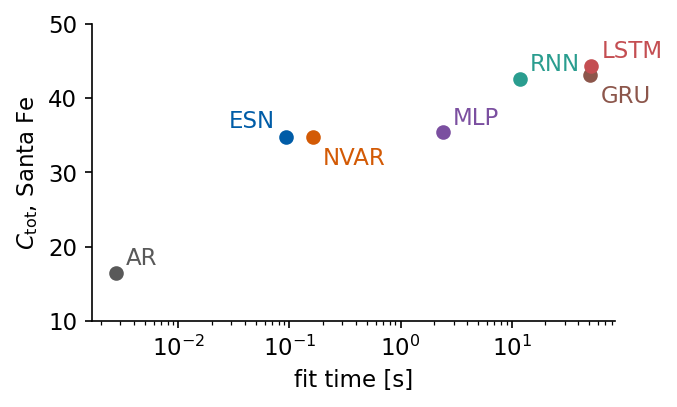

In [28]:
LABEL_POS = {"AR": (5, 4, "left"), "NVAR": (5, -13, "left"), "ESN": (-5, 5, "right"), "MLP": (5, 4, "left"),
             "RNN": (5, 4, "left"), "GRU": (5, -13, "left"), "LSTM": (5, 4, "left")}
# ESN and NVAR have nearly the same C_tot on Santa Fe: the label of the faster one goes to the left, the other one below right
fast, slow = sorted(("ESN", "NVAR"), key=lambda m: cost[m])
LABEL_POS[fast], LABEL_POS[slow] = (-5, 5, "right"), (5, -13, "left")
with mpl.rc_context(SLIDE_RC):
    fig, ax = plt.subplots(figsize=(4.4, 2.6), layout="constrained")
    for m in HERE + NETS:
        x_, y_ = cost[m], ctot_all["SantaFe"][m]
        ax.scatter(x_, y_, s=36, color=STYLE[m]["color"], zorder=3)
        dx, dy, ha = LABEL_POS[m]
        ax.annotate(m, (x_, y_), textcoords="offset points", xytext=(dx, dy), ha=ha, color=STYLE[m]["color"])
    ax.set_xscale("log"); ax.set_xlabel("fit time [s]"); ax.set_ylabel(r"$C_{\rm tot}$, Santa Fe")
    ax.set_ylim(10, 50)
    save(fig, "fig_lab046_cost"); plt.show()

One ESN fit takes 92 ms including the reservoir run. The trained networks need 2.4 s (MLP) to 52 s (LSTM), between 26 and 561 times the ESN fit, and the three trained recurrent networks alone between 128 (RNN) and 561 (LSTM) times. The trained recurrent networks keep a clear lead on Santa Fe, 44.3 for the LSTM against 34.7 for the ESN, and on Lorenz, 45.1 for the GRU against 39.2. On the Mackey–Glass signals the ESN stays within 1.6 of the best trained network. The number of trained parameters does not order the models by cost. The ESN readout has 15050 parameters and the LSTM 6002, but the readout is the solution of one linear system, while the LSTM weights come out of a nonconvex optimisation through time. One step ahead, the ESN reaches $C=0.987$ on Santa Fe, above the best trained network with $C=0.959$, so the ranking depends on the horizon.

<hr/>
## Summary

An echo state network is a driven random dynamical system with a trained linear readout. Its state forgets the initial condition when the recurrence contracts, which we tested directly. For the Santa Fe input the threshold spectral radius grows from 1.0 to 1.45 as the input scaling grows from 0.1 to 2, so the rule $\rho<1$ is a working rule for weak inputs. The leak rate lengthens the memory through the effective decay $(1-\alpha)+\alpha\rho$. A linear reservoir of three units stores the last three inputs, and a nonlinear reservoir with 50 units stores up to about 20 past inputs, with the largest memory capacity just below $\rho=1$ in this test. A reservoir with 100 units solves NARMA-2 and NARMA-5, where a linear readout of the inputs fails. Our ESN implementation in JAX agrees with ReservoirPy to round-off, and reservoirs drawn by the library forecast as well as ours.

On the benchmark signals the ESN with 300 units exceeds the best AR and NVAR models on Lorenz and on Mackey–Glass at 25 and 35, with the largest gain on Lorenz, 39.2 against 15.4. All models except persistence reach the maximum on Mackey–Glass at 15. On Santa Fe the reservoir of seed 0 ties NVAR, and four other random reservoirs stay between 1.4 and 3.1 below the reservoir of seed 0. The trained recurrent networks keep a lead on Lorenz and Santa Fe at a fitting cost 128 to 561 times higher. All results refer to the signals, settings and random draws of this notebook.

## References

- H. Jaeger, *The "echo state" approach to analysing and training recurrent neural networks*, GMD Report 148, German National Research Center for Information Technology (2001), [pdf](https://www.ai.rug.nl/minds/uploads/EchoStatesTechRep.pdf)
- W. Maass, T. Natschläger, H. Markram, *Real-time computing without stable states: a new framework for neural computation based on perturbations*, Neural Comput. **14**, 2531 (2002), [doi:10.1162/089976602760407955](https://doi.org/10.1162/089976602760407955)
- M. Lukoševičius, H. Jaeger, *Reservoir computing approaches to recurrent neural network training*, Comput. Sci. Rev. **3**, 127 (2009), [doi:10.1016/j.cosrev.2009.03.005](https://doi.org/10.1016/j.cosrev.2009.03.005)
- B. O. Koopman, *Hamiltonian systems and transformation in Hilbert space*, PNAS **17**, 315 (1931), [doi:10.1073/pnas.17.5.315](https://doi.org/10.1073/pnas.17.5.315)
- E. Bollt, *On explaining the surprising success of reservoir computing forecaster of chaos? The universal machine learning dynamical system with contrast to VAR and DMD*, Chaos **31**, 013108 (2021), [doi:10.1063/5.0024890](https://doi.org/10.1063/5.0024890)
- A. E. Hoerl, R. W. Kennard, *Ridge regression: biased estimation for nonorthogonal problems*, Technometrics **12**, 55 (1970), [doi:10.1080/00401706.1970.10488634](https://doi.org/10.1080/00401706.1970.10488634)
- I. B. Yildiz, H. Jaeger, S. J. Kiebel, *Re-visiting the echo state property*, Neural Netw. **35**, 1 (2012), [doi:10.1016/j.neunet.2012.07.005](https://doi.org/10.1016/j.neunet.2012.07.005)
- J. Dambre, D. Verstraeten, B. Schrauwen, S. Massar, *Information processing capacity of dynamical systems*, Sci. Rep. **2**, 514 (2012), [doi:10.1038/srep00514](https://doi.org/10.1038/srep00514)
- A. F. Atiya, A. G. Parlos, *New results on recurrent network training: unifying the algorithms and accelerating convergence*, IEEE Trans. Neural Netw. **11**, 697 (2000), [doi:10.1109/72.846741](https://doi.org/10.1109/72.846741)
- D. J. Gauthier, E. Bollt, A. Griffith, W. A. S. Barbosa, *Next generation reservoir computing*, Nat. Commun. **12**, 5564 (2021), [doi:10.1038/s41467-021-25801-2](https://doi.org/10.1038/s41467-021-25801-2)

The last cell collects the numbers of this notebook in a JSON file and as LaTeX macros.

In [29]:
nums["runtime_s"] = round(time.time() - t_start, 1)
def to_py(o):
    if isinstance(o, dict): return {str(k): to_py(v) for k, v in o.items()}
    if isinstance(o, (list, tuple)): return [to_py(v) for v in o]
    if isinstance(o, (np.floating, np.integer)): return o.item()
    if isinstance(o, np.ndarray): return to_py(o.tolist())
    return o
with open(f"{OUT}/numbers_lab046.json", "w") as fh:
    json.dump(to_py(nums), fh, indent=1)

def sci(x, d=1):
    m, e = f"{x:.{d}e}".split("e")
    return f"{m}\\times10^{{{int(e)}}}"
SIGTAG = {"Lorenz": "Lorenz", "MG15": "MGfifteen", "MG25": "MGtwentyfive", "MG35": "MGthirtyfive", "SantaFe": "SantaFe"}
RHOTAG = {0.5: "Half", 0.8: "EightTenths", 0.95: "NinetyFive", 1.0: "One", 1.1: "OneTenth", 1.2: "OnePointTwo", 2.0: "Two"}
macros = {}
macros["SigmaMaxHundred"] = f"{nums['esp']['sigma_max_rho1']:.2f}"
macros["RhoBoundHundred"] = f"{nums['esp']['rho_bound']:.2f}"
for key, tag in (("rho0.8", "EightTenths"), ("rho1.0", "One"), ("rho1.2", "OnePointTwo"), ("rho2.0", "Two"),
                 ("rho1.2_noinput", "NoInput")):
    macros[f"EspEnd{tag}"] = sci(max(nums["esp"][key]["d_end"], 1e-17))
for si, tag in ((0.1, "PointOne"), (0.5, "Half"), (1.0, "One"), (2.0, "Two")):
    rc = nums["esp_rho_crit"][str(si)]
    macros[f"EspRhoCrit{tag}"] = f"{rc:.2f}" if rc is not None else "{>}2"
for rho_ in (0.5, 0.8, 0.95, 1.1):
    macros[f"MC{RHOTAG[rho_]}"] = f"{nums['memory_capacity'][f'rho_{rho_}']:.1f}"
macros["MCBest"] = f"{nums['mc_vs_rho']['mc_best']:.1f}"
macros["MCBestRho"] = f"{nums['mc_vs_rho']['rho_best']:.1f}"
macros["MCLinearThreeRandomSum"] = f"{nums['linear3']['random']['sum_d0']:.2f}"
macros["DecayAlphaPointThreeRhoEightTenths"] = f"{nums['decay']['a0.3_r0.8']['formula']:.2f}"
macros["MemTimeAlphaOneRhoEightTenths"] = f"{nums['decay']['a1.0_r0.8']['t_mem']:.1f}"
macros["MemTimeAlphaPointThreeRhoEightTenths"] = f"{nums['decay']['a0.3_r0.8']['t_mem']:.1f}"
for n, tag in ((2, "Two"), (5, "Five"), (10, "Ten")):
    for mk, mt in (("linear", "Linear"), ("NVAR", "NVAR"), ("ESN", "ESN")):
        v = narma_tab[n][mk]
        macros[f"Narma{tag}{mt}"] = f"{v:.3f}" if v >= 1e-2 else sci(v)      # two significant figures below 0.01
for n in SIGNALS:
    for m in ("persistence", "AR", "NVAR", "ESN"):
        macros[f"Ctot{m.capitalize() if m == 'persistence' else m}{SIGTAG[n]}"] = f"{res[n][m]['Ctot']:.1f}"
    for m in NETS:
        macros[f"Ctot{m}{SIGTAG[n]}"] = f"{trained['Ctot'][n][m]:.1f}"
    e = res[n]["ESN"]
    macros[f"EsnRho{SIGTAG[n]}"] = f"{e['rho']}"; macros[f"EsnSigma{SIGTAG[n]}"] = f"{e['sigma_in']}"
    macros[f"EsnAlpha{SIGTAG[n]}"] = f"{e['alpha']}"
    macros[f"OneStepCESN{SIGTAG[n]}"] = f"{nums['one_step'][n]['C']:.3f}"
    macros[f"SeedMin{SIGTAG[n]}"] = f"{min(nums['seed_Ctot'][n]):.1f}"
    macros[f"SeedMax{SIGTAG[n]}"] = f"{max(nums['seed_Ctot'][n]):.1f}"
    macros[f"RpyCtot{SIGTAG[n]}"] = f"{rpy_ctot[n]:.1f}"
    macros[f"SeedSpread{SIGTAG[n]}"] = f"{nums['seed_spread'][n]:.1f}"     # from the unrounded C_tot values
macros["EspFirstFitMax"] = f"{max(v['d_first_fit'] for v in nums['esp_selected'].values()):.2f}"
macros["WashoutCtotChangeMax"] = f"{max(abs(nums['esp_selected'][n]['Ctot_washout263'] - res[n]['ESN']['Ctot']) for n in SIGNALS):.2f}"
if trained:
    macros["OneStepBestTrainedSantaFe"] = f"{best_other:.3f}"
    # largest lead of the best trained network over the ESN on the three Mackey-Glass records
    macros["MGGapTrainedESN"] = f"{max(max(trained['Ctot'][n][m] for m in NETS) - res[n]['ESN']['Ctot'] for n in ('MG15', 'MG25', 'MG35')):.1f}"
for key, tag in (("rho0.8", "EightTenths"), ("rho1.2", "OnePointTwo")):
    macros[f"FadingEnd{tag}"] = sci(max(nums["fading"][key]["d_end"], 1e-17))
macros["RpyStatesDiff"] = sci(nums["rpy_states_diff"]); macros["RpyPredDiff"] = sci(nums["rpy_pred_diff"])
for m in HERE:
    macros[f"FitTime{m}"] = f"{1000 * cost[m]:.0f}"                 # milliseconds
for m in NETS:
    macros[f"FitTime{m}"] = f"{cost[m]:.0f}"                        # seconds
    macros[f"FitRatio{m}"] = f"{cost[m] / cost['ESN']:.0f}"
for m in ("ESN",) + NETS:
    macros[f"Params{m}"] = str(n_trained[m])
macros["SigmaMaxThreeHundred"] = f"{nums['W300']['sigma_max_rho1']:.2f}"
macros["EsnSearchTime"] = f"{nums['esn_search_time_s']:.0f}"
macros["Runtime"] = f"{nums['runtime_s'] / 60:.1f}"
bad = [k for k in macros if not k.isalpha()]
assert not bad, bad
with open(f"{OUT}/nb_numbers_lab046.tex", "w") as fh:
    for k, val in macros.items():
        fh.write(f"\\newcommand{{\\labfortysix{k}}}{{{val}}}\n")
print(f"{len(macros)} macros written; total runtime {nums['runtime_s'] / 60:.1f} min")

137 macros written; total runtime 4.0 min
